# Historical IR: a retrieval system for 19th-century newspapers
## [TG3E: Temporally and Geographically Expanded Efficient Entity-Aware Retrieval-Augmented Generation]


### **Authors:** Valentyn Piskovskyi, Simone Pedico 

---


# Setup: download data from Hugging Face

All data (dataset, preprocessed corpus/queries, Terrier and dense indexes, QA runs) is downloaded from the Hugging Face dataset [`siiimo/TG3E`](https://huggingface.co/datasets/siiimo/TG3E). Files generated by the notebook are stored in the local `outputs/` folder.

In [ ]:
import os
import shutil
from huggingface_hub import snapshot_download

# Hugging Face repository with all data and pre-computed indexes / runs
HF_REPO_ID = "siiimo/TG3E"
HF_DIR = snapshot_download(repo_id=HF_REPO_ID, repo_type="dataset", local_dir="TG3E_hf")

def hf_path(*parts):
    return os.path.join(HF_DIR, *parts)

# Local folder for everything generated by this notebook (runs, results, preprocessed data)
WORK_DIR = "outputs"
os.makedirs(WORK_DIR, exist_ok=True)

# Preprocessed corpus / queries (Phase 2 preprocessing, ~1.5h+ to regenerate)
CORPUS_PREPROCESSED_HF    = hf_path("corpus_dataframe_tc_lem_ner_te_geo_all.json")
CORPUS_PREPROCESSED_LOCAL = os.path.join(WORK_DIR, "corpus_dataframe_tc_lem_ner_te_geo_all.json")
QUERIES_PREPROCESSED_HF    = hf_path("queries_dataframe_tc_lem_ner_te_geo_all.json")
QUERIES_PREPROCESSED_LOCAL = os.path.join(WORK_DIR, "queries_dataframe_tc_lem_ner_te_geo_all.json")

# QA runs (RAG answers)
QA_RUNS_HF    = hf_path("qa_runs")
QA_RUNS_LOCAL = os.path.join(WORK_DIR, "qa_runs")

def first_existing(*paths):
    for p in paths:
        if os.path.exists(p):
            return p
    return None

def load_corpus_preprocessed():
    import pandas as pd
    p = first_existing(CORPUS_PREPROCESSED_HF, CORPUS_PREPROCESSED_LOCAL)
    if p is None:
        raise FileNotFoundError(
            "corpus_dataframe_tc_lem_ner_te_geo_all.json not found on Hugging Face nor locally. "
            "Upload it or run the 'Phase 2: Preprocessing' section first "
            f"(it saves the file to {CORPUS_PREPROCESSED_LOCAL})."
        )
    print("Loading preprocessed corpus from", p)
    return pd.read_json(p)

def load_queries_preprocessed():
    import pandas as pd
    p = first_existing(QUERIES_PREPROCESSED_HF, QUERIES_PREPROCESSED_LOCAL)
    if p is None:
        raise FileNotFoundError("queries_dataframe_tc_lem_ner_te_geo_all.json not found.")
    print("Loading preprocessed queries from", p)
    return pd.read_json(p)

# Report which expected artefacts are available in the HF snapshot
expected = [
    "dataset/train.json", "dataset/validation.json", "dataset/test.json",
    "corpus_dataframe_tc_lem_ner_te_geo_all.json", "queries_dataframe_tc_lem_ner_te_geo_all.json",
    "timeRetrieval_index", "timeRetrieval_tc_index", "timeRetrieval_lem_index", "timeRetrieval_te_geo_index",
    "timeRetrieval_ne_index",
    "all-MiniLM-L6-v2_index", "snowflake-arctic-embed-xs_index", "bge-base-en-v1.5_index",
    "all-MiniLM-L6-v2_index_tc", "all-MiniLM-L6-v2_index_lem", "all-MiniLM-L6-v2_index_te",
    "all-MiniLM-L6-v2_index_geo", "all-MiniLM-L6-v2_index_ner", "qa_runs",
]
for e in expected:
    print(("OK      " if os.path.exists(hf_path(e)) else "MISSING ") + e)

# Dataset Preparation

## Download and Inspect the Collection

The dataset was created from the Chronicling America collection — over 21 million digitized newspaper pages (1756–1963) curated by the Library of Congress and NEH. They used 39,330 pages (1800–1920), representing 53 US states, to ensure wide geographic and temporal coverage.

Source: https://dl.acm.org/doi/pdf/10.1145/3626772.3657891

GitHub: https://github.com/DataScienceUIBK/ChroniclingAmericaQA?tab=readme-ov-file

In [ ]:
import os
import shutil
import json


# If a file is missing there, it is downloaded from the original public HF dataset.
file_configs = {
    "test.json": "https://huggingface.co/datasets/Bhawna/ChroniclingAmericaQA/resolve/main/test.json?download=true",
    "train.json": "https://huggingface.co/datasets/Bhawna/ChroniclingAmericaQA/resolve/main/train.json?download=true",
    "validation.json": "https://huggingface.co/datasets/Bhawna/ChroniclingAmericaQA/resolve/main/dev.json?download=true"
}

# Process each file
for file_name, download_url in file_configs.items():
    local_path = file_name
    hf_file_path = hf_path("dataset", file_name)

    if os.path.exists(local_path):
        print(f"'{file_name}' already exists locally. Skipping.")
    elif os.path.exists(hf_file_path):
        print(f"'{file_name}' found in the HF snapshot. Copying to local.")
        shutil.copy(hf_file_path, local_path)
    else:
        print(f"'{file_name}' not found in {HF_REPO_ID}. Downloading from the original HF dataset.")
        # Execute curl command to download
        !curl -L "{download_url}" -o "{local_path}"

files = ["train.json", "validation.json", "test.json"]

for path in files:
    print(f"\n===== {path} =====")
    try:
        with open(path, "r", encoding="utf-8") as f:
            # Read a few hundred characters to see what kind of JSON it is
            head = f.read(500)
            print("Preview of first 500 characters:\n")
            print(head[:500])
        # Try to load only part of the file
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        if isinstance(data, list):
            print(f"\nLoaded {len(data)} items (list).")
            print("Dictionary keys:", list(data[0].keys()))
            print(json.dumps(data[0], indent=2)[:600])
        elif isinstance(data, dict):
            print("\nTop-level is a dictionary. Keys:", list(data.keys()))
            for k, v in data.items():
                if isinstance(v, list):
                    print(f"Key '{k}' contains a list of {len(v)} items.")
                    if v:
                        print("First item keys:", list(v[0].keys()))
                        print(json.dumps(v[0], indent=2)[:600])
                        break
        else:
            print(f"Unexpected top-level type: {type(data)}")
    except Exception as e:
        print(f"Could not parse {path} as JSON: {e}")

Mounted at /content/drive
'test.json' not found locally or in Drive. Downloading from internet.
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  1075  100  1075    0     0   3129      0 --:--:-- --:--:-- --:--:--  3125
100 71.5M  100 71.5M    0     0  36.9M      0  0:00:01  0:00:01 --:--:-- 87.7M
'train.json' not found locally or in Drive. Downloading from internet.
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  1079  100  1079    0     0   5296      0 --:--:-- --:--:-- --:--:--  5315
100 1315M  100 1315M    0     0  65.8M      0  0:00:19  0:00:19 --:--:-- 78.5M
'validation.json' not found locally or in Drive. Downloading from internet.
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Uploa

## Create the Document Collection

To do that, we create a new json file that contains the 'para_id', 'context', 'raw_ocr', 'publication_date' keys, for all para_id in the collection.

para_id: is the id of a paragraph of a news paper page.

In [ ]:
inputs = ["train.json", "validation.json", "test.json"]
output = "document_collection.json"

def load_list_or_empty(path):
    if not os.path.exists(path) or os.path.getsize(path) == 0:
        print(f"Skipping {path} because it is missing or empty")
        return []
    try:
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        if isinstance(data, list):
            return data
        print(f"Skipping {path} because it is not a list at the top level")
        return []
    except json.JSONDecodeError:
        print(f"Skipping {path} because it is not valid JSON")
        return []

def project(recs):
    out = []
    for r in recs:
        out.append({
            "para_id": r.get("para_id", ""),
            "context": r.get("context", ""),
            "raw_ocr": r.get("raw_ocr", ""),
            "publication_date": r.get("publication_date", "")
        })
    return out

all_recs = []
for p in inputs:
    recs = load_list_or_empty(p)
    print(f"Loaded {len(recs)} records from {p}")
    all_recs.extend(project(recs))

# deduplicate by para_id keeping the first one seen
uniq = {}
for rec in all_recs:
    pid = rec.get("para_id", "")
    if pid and pid not in uniq:
        uniq[pid] = rec

result = list(uniq.values())

with open(output, "w", encoding="utf-8") as f:
    json.dump(result, f, ensure_ascii=False, indent=2)

print(f"Wrote {len(result)} records to {output}")
print(json.dumps(result[:3], indent=2))

Loaded 439302 records from train.json
Loaded 24111 records from validation.json
Loaded 24084 records from test.json
Wrote 131921 records to document_collection.json
[
  {
    "para_id": "New_Hampshire_18070804_1",
    "context": "Aiscellaneous Repository. From the Albany Register, WAR, OR A PROSPECT OF IT, From recent instances of British Outrage. BY: WILLIAM RAY, Author of the contemplated publication, entitled, \u201cHorrors of Slavery, or the American Turf in Tripoli,\u201d VOTARIES of Freedom, arm! The British Lion roars! Legions of Valor, take th\u2019 alarm\u2014; Rash, rush to guard our shores! Behold the horrid deed\u2014 Your brethren gasping lie! Beneath a tyrant\u2019s hand they bleed\u2014 They groan\u2014they faint\u2014they die. Veterans of seventy-six, Awake the slumbering sword;\u2014 Hearts of your murderous foes transfix\u2014 'Tis vengeance gives the word. Remember Lexington, And Bunker\u2019s tragic hill; \u201cThe same who spilt your blood thereon, Your blood again

## Create the Test Queries Data Structure

We keep the first 10.000 queries due to memory errors in the free colab version.

To be comparable, please keep the top 10.000 queries for evaluation.

In [ ]:
import json
import re
import unicodedata
import string

input_file = "test.json"
output_file = "test_queries.json"

# Load the data
with open(input_file, "r", encoding="utf-8") as f:
    data = json.load(f)

def clean_question(text):
    if not isinstance(text, str):
        return ""
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(rf"[{re.escape(string.punctuation)}]", " ", text)  # remove punctuation
    text = re.sub(r"\s+", " ", text)  # collapse multiple spaces
    return text.strip()

# Extract and clean
queries = [
    {
        "query_id": item.get("query_id", ""),
        "question": clean_question(item.get("question", "")),
        "answer": item.get("answer", ""),
        "org_answer": item.get("org_answer", "")
    }
    for item in data
]

# Sort by query_id (assuming numeric)
queries = sorted(queries, key=lambda x: int(x["query_id"]) if str(x["query_id"]).isdigit() else x["query_id"])

# Keep only the first 10,000
queries = queries[:10000]

# Save new JSON
with open(output_file, "w", encoding="utf-8") as f:
    json.dump(queries, f, ensure_ascii=False, indent=2)

print(f"Saved {len(queries)} entries to {output_file}")
print(json.dumps(queries[:3], indent=2))

Saved 10000 entries to test_queries.json
[
  {
    "query_id": "test_1",
    "question": "How many lots did Thomas Peirce have",
    "answer": "183",
    "org_answer": "183"
  },
  {
    "query_id": "test_10",
    "question": "Who gave Hamilton the substance of what he had proposed on the part of General Hamilton",
    "answer": "Taylor",
    "org_answer": "Taylor"
  },
  {
    "query_id": "test_100",
    "question": "Who informs his FRIENDS and the PUBLIC that he has taken that justly celebrated INN in this city",
    "answer": "WILLIAM EATON",
    "org_answer": "WILLIAM EATON"
  }
]


## Create the Qrels for the test set

In [ ]:
input_file = "test.json"
qrels_file = "test_qrels.json"
answers_file = "test_query_answers.json"

# Load the data
with open(input_file, "r", encoding="utf-8") as f:
    data = json.load(f)

# Build the qrels file: query_id, iteration=0, para_id, relevance=1
qrels = [
    {
        "query_id": item.get("query_id", ""),
        "iteration": 0,
        "para_id": item.get("para_id", ""),
        "relevance": 1
    }
    for item in data
]

# Build the query_answers file: same plus answer and org_answer
query_answers = [
    {
        "query_id": item.get("query_id", ""),
        "iteration": 0,
        "para_id": item.get("para_id", ""),
        "relevance": 1,
        "answer": item.get("answer", ""),
        "org_answer": item.get("org_answer", "")
    }
    for item in data
]

# Save both files
with open(qrels_file, "w", encoding="utf-8") as f:
    json.dump(qrels, f, ensure_ascii=False, indent=2)

with open(answers_file, "w", encoding="utf-8") as f:
    json.dump(query_answers, f, ensure_ascii=False, indent=2)

print(f"Saved {len(qrels)} entries to {qrels_file}")
print(f"Saved {len(query_answers)} entries to {answers_file}")
print("Sample qrels entry:", qrels[0])
print("Sample query_answers entry:", query_answers[0])

Saved 24084 entries to test_qrels.json
Saved 24084 entries to test_query_answers.json
Sample qrels entry: {'query_id': 'test_1', 'iteration': 0, 'para_id': 'New_Hampshire_18030125_16', 'relevance': 1}
Sample query_answers entry: {'query_id': 'test_1', 'iteration': 0, 'para_id': 'New_Hampshire_18030125_16', 'relevance': 1, 'answer': '183', 'org_answer': '183'}


# Installation and import of libraries

In [ ]:
!pip install python-terrier pyterrier-dr -q
!pip install symspellpy spacy dateparser -q

  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.2/59.2 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 208.3/208.3 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 866.1/866.1 kB 45.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.3/61.3 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 82.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 86.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 304.8/304.8 kB 31.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.0/149.0 kB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 132.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 50.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 315.5/3

In [ ]:
# Utility libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import shutil
from collections import Counter
from tqdm import tqdm
from tqdm.auto import tqdm
import pkg_resources

# PyTerrier
import pyterrier as pt
from pyterrier.measures import *

# Pre-processing
import re
import spacy
from symspellpy import SymSpell, Verbosity
import dateparser
from datetime import date, datetime

# Second stage
from pyterrier_dr import SBertBiEncoder, BiScorer, BiEncoder, FlexIndex

/tmp/ipython-input-4127946039.py:11: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  import pkg_resources


Helper functions to load indexes and runs from the Hugging Face snapshot (or build them locally if missing)

In [ ]:
# Helper: load a Terrier index from the HF snapshot, otherwise build it locally
def load_or_build_terrier_index(name, text_attr, records_fn):
    hf_idx = hf_path(name)
    local_idx = os.path.join(WORK_DIR, name)
    for p in (hf_idx, local_idx):
        if os.path.exists(os.path.join(p, "data.properties")):
            idx = pt.IndexFactory.of(p)
            print(f"Index loaded from disk: {p}")
            return idx

    print(f"Index '{name}' not found: building it in {local_idx}")
    if os.path.exists(local_idx):
        shutil.rmtree(local_idx)
    os.makedirs(local_idx, exist_ok=True)
    indexer = pt.IterDictIndexer(
        local_idx,
        meta={"docno": 64},            # store docno as metadata (up to 64 characters)
        text_attrs=[text_attr],        # which field(s) contain the text
        meta_reverse=["docno"],        # enable reverse lookup on docno
        pretokenised=False,
        fields=False,
        threads=1,
    )
    ref = indexer.index(records_fn())
    idx = pt.IndexFactory.of(ref)
    print("Index location:", local_idx)
    print("Indexed documents:", idx.getCollectionStatistics().getNumberOfDocuments())
    return idx

# Helper: path of a dense (FlexIndex) index: HF snapshot if present, otherwise local
def dense_index_path(name):
    p = hf_path(name)
    return p if os.path.exists(p) and os.listdir(p) else os.path.join(WORK_DIR, name)

# Helper: DLH13 first-stage run (loaded from a previous local run, otherwise computed)
RUN_DLH13_CSV = os.path.join(WORK_DIR, "run_dlh13.csv")

def get_run_dlh13(queries_df):
    if os.path.exists(RUN_DLH13_CSV):
        print("Loading DLH13 run from", RUN_DLH13_CSV)
        return pd.read_csv(RUN_DLH13_CSV)
    print("DLH13 run not found: computing it on the main index")
    main_index = load_or_build_terrier_index(
        "timeRetrieval_index", "text",
        lambda: pd.read_json("document_collection.json")
                  .rename(columns={"para_id": "docno", "context": "text"})
                  .to_dict(orient="records"))
    run = pt.terrier.Retriever(main_index, wmodel="DLH13", verbose=True).transform(queries_df)
    run.to_csv(RUN_DLH13_CSV, index=False)
    return run

# Phase 1: Experiments with Basic Architectures

## Retrieval

Data and pre-computed indexes come from the Hugging Face snapshot downloaded in the *Setup* section.

In [ ]:
# (Google Drive is no longer used: everything is loaded from Hugging Face)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Prepare dataframe for PyTerrier: needs columns 'docno' and 'text'

In [ ]:
df = pd.read_json("document_collection.json")
corpus_dataframe = df.rename(columns={"para_id": "docno", "context": "text"})
print(df.head())

                    para_id  \
0  New_Hampshire_18070804_1   
1  New_Hampshire_18070804_4   
2  New_Hampshire_18070804_5   
3  New_Hampshire_18070804_8   
4  New_Hampshire_18070804_9   

                                             context  \
0  Aiscellaneous Repository. From the Albany Regi...   
1  Surely he above the rest of his fellow mortals...   
2  At Westmoreland, Mrs. Sally Lincoln, wife of M...   
3  Upon the correction of this remedy the stomach...   
4  Also FOR SALE AS ABOVE, NEW GOODS, STEPHEN HAR...   

                                             raw_ocr publication_date  
0  fAiscellancous Bepogitory.\n. dvom the Albany ...       1807-08-04  
1  Surely he a\nbove the rest of his fellow morta...       1807-08-04  
2  At Weltmoreland, Mrs. Sally Liacoln, wife\n~of...       1807-08-04  
3  tion of this remedy the flomach is invariably\...       1807-08-04  
4  *°\n, ALSO POR SALE AS ABOVE,\no NEW-GEODS, -\...       1807-08-04  


### Main index

Indexing

In [ ]:
# Load the main index from the HF snapshot (or build it if missing)
index = load_or_build_terrier_index(
    "timeRetrieval_index", "text",
    lambda: corpus_dataframe.to_dict(orient="records"))

Index loaded from disk.


Run First Stage Retrieval using one of the models among TF-IDF, BM25, PL2 and DLH13

In [ ]:
# Qrels dataframe
qrels_df = pd.DataFrame(qrels).rename(columns =
 {'query_id' : 'qid', 'para_id' : 'docno', 'relevance' : 'label'})[['qid', 'docno', 'label']]
# Queries dataframe
queries_df = pd.DataFrame(queries).rename(columns =
 {'query_id' : 'qid', 'question': 'query'})[['qid', 'query']]

tfidf = pt.terrier.Retriever(index, wmodel="TF_IDF", verbose = True)
bm25 = pt.terrier.Retriever(index, wmodel="BM25", verbose = True)
pl2 = pt.terrier.Retriever(index, wmodel="PL2", verbose = True)
dlh13 = pt.terrier.Retriever(index, wmodel="DLH13", verbose = True)

run_tfidf = tfidf.transform(queries_df)
run_bm25  = bm25.transform(queries_df)
run_pl2 = pl2.transform(queries_df)
run_dlh13  = dlh13.transform(queries_df)

# Save results locally
run_bm25.to_csv(os.path.join(WORK_DIR, "run_bm25.csv"), index=False)
run_tfidf.to_csv(os.path.join(WORK_DIR, "run_tfidf.csv"), index=False)
run_pl2.to_csv(os.path.join(WORK_DIR, "run_pl2.csv"), index=False)
run_dlh13.to_csv(RUN_DLH13_CSV, index=False)

'\nrun_bm25.to_csv(\n    "/content/drive/MyDrive/informationRetrievalProject/run_bm25.csv",\n    index=False\n)\n\nrun_tfidf.to_csv(\n    "/content/drive/MyDrive/informationRetrievalProject/run_tfidf.csv",\n    index=False\n)\n\nrun_pl2.to_csv(\n    "/content/drive/MyDrive/informationRetrievalProject/run_pl2.csv",\n    index=False\n)\n\nrun_dlh13.to_csv(\n    "/content/drive/MyDrive/informationRetrievalProject/run_dlh13.csv",\n    index=False\n)\n'

### Load preprocessed dataframe

In [ ]:
corpus_dataframe_preprocessed = load_corpus_preprocessed()
corpus_dataframe_preprocessed.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,docno,text,raw_ocr,publication_date,text_tc,text_tc_lem,named_entities,normalized_dates,locations_text
0,New_Hampshire_18070804_1,Aiscellaneous Repository. From the Albany Regi...,fAiscellancous Bepogitory.\n. dvom the Albany ...,1807-08-04,Miscellaneous Repository fRom the aLbany rEgis...,aiscellaneous repository from the albany regis...,"[the Albany Register, WAR, British Outrage, Ho...",[],"[Tripoli, War]"
1,New_Hampshire_18070804_4,Surely he above the rest of his fellow mortals...,Surely he a\nbove the rest of his fellow morta...,1807-08-04,Surely he above the rest of his fellow mortals...,surely he above the rest of his fellow mortal ...,"[France, de Rosemberg, 83, France, the Legion ...","[1807-02-04, 1807-08-04]","[Andover, Baltimore, Brunswick, Chesterfield, ..."
2,New_Hampshire_18070804_5,"At Westmoreland, Mrs. Sally Lincoln, wife of M...","At Weltmoreland, Mrs. Sally Liacoln, wife\n~of...",1807-08-04,At Westmorland mrS salLy linColn wife of or sP...,at westmoreland mrs. sally lincoln wife of mr....,"[Westmoreland, Sally Lincoln, Spencer L., 28, ...","[1807-07-28, 1807-08-01, 1807-08-28]","[Henrico, NEW GONDOLA, New Hampshire Fire]"
3,New_Hampshire_18070804_8,Upon the correction of this remedy the stomach...,tion of this remedy the flomach is invariably\...,1807-08-04,Upon the correction of this remedy the stomach...,upon the correction of this remedy the stomach...,"[Bitters, Newbury Street, Winter Street, Bosto...",[],"[Boston, New England, Newbury Street, Winter S..."
4,New_Hampshire_18070804_9,"Also FOR SALE AS ABOVE, NEW GOODS, STEPHEN HAR...","*°\n, ALSO POR SALE AS ABOVE,\no NEW-GEODS, -\...",1807-08-04,Also FOR SALE AS ABOVE NEW GOODS STEPHEN HARDY...,also for sale as above new goods stephen hardy...,"[NEW GOODS, STEPHEN HARDY, Market Street, JEWE...",[],"[Market Street, NEW GOODS, Trays]"


### Corrected Text Index

Indexing

In [ ]:
index_tc = load_or_build_terrier_index(
    "timeRetrieval_tc_index", "text_tc",
    lambda: corpus_dataframe_preprocessed.to_dict(orient="records"))

Java started (triggered by TerrierIndexer.__init__) and loaded: pyterrier.java.colab, pyterrier.java, pyterrier.java.24, pyterrier.terrier.java [version=5.11 (build: craig.macdonald 2025-01-13 21:29), helper_version=0.0.8]


14:40:46.848 [ForkJoinPool-1-worker-1] WARN org.terrier.structures.indexing.Indexer -- Adding an empty document to the index (Michigan_18370308_24) - further warnings are suppressed
14:41:01.810 [ForkJoinPool-1-worker-1] WARN org.terrier.structures.indexing.Indexer -- Indexed 1 empty documents
Index location: /content/drive/MyDrive/projectIR/projectIR/timeRetrieval_tc_index
Indexed documents: 131921


Run First Stage Retrieval using DLH13 on the (OCR-corrected) original text further corrected with SymSpell

In [ ]:
dlh13_tc = pt.terrier.Retriever(index_tc, wmodel="DLH13", verbose = True)
run_dlh13_tc = dlh13_tc.transform(queries_df)
run_dlh13_tc.to_csv(os.path.join(WORK_DIR, "run_dlh13_tc.csv"), index=False)

del index_tc
del dlh13_tc

TerrierRetr(DLH13):   0%|          | 0/10000 [00:00<?, ?q/s]

### Lemmatized Text Index

Indexing

In [ ]:
index_lem = load_or_build_terrier_index(
    "timeRetrieval_lem_index", "text_tc_lem",
    lambda: corpus_dataframe_preprocessed.to_dict(orient="records"))

14:53:12.646 [ForkJoinPool-2-worker-1] WARN org.terrier.structures.indexing.Indexer -- Adding an empty document to the index (Michigan_18370308_24) - further warnings are suppressed
14:53:26.875 [ForkJoinPool-2-worker-1] WARN org.terrier.structures.indexing.Indexer -- Indexed 1 empty documents
Index location: /content/drive/MyDrive/projectIR/projectIR/timeRetrieval_lem_index
Indexed documents: 131921


Run First Stage Retrieval with lemmatized text

In [ ]:
dlh13_lem = pt.terrier.Retriever(index_lem, wmodel="DLH13", verbose = True)
run_dlh13_lem  = dlh13_lem.transform(queries_df)
run_dlh13_lem.to_csv(os.path.join(WORK_DIR, "run_dlh13_lem.csv"), index=False)

del index_lem
del dlh13_lem

TerrierRetr(DLH13):   0%|          | 0/10000 [00:00<?, ?q/s]

### Temporally and Geographically Expanded Index

Combination of the original text with detected dates

In [ ]:
# Create column with injected dates and geographical locations
def combine_dates_and_pub_date(normalized_dates_list, publication_date_str):
    # Ensure it's a list for mutation
    combined_dates = list(normalized_dates_list)
    if publication_date_str and publication_date_str not in combined_dates:
        combined_dates.append(publication_date_str)
    return sorted(list(set(combined_dates)))

corpus_dataframe_preprocessed["expanded_dates"] = corpus_dataframe_preprocessed.apply(
    lambda row: combine_dates_and_pub_date(row["normalized_dates"], row["publication_date"]),
    axis=1
)

corpus_dataframe_preprocessed["text_te_geo"] = corpus_dataframe_preprocessed["text_tc_lem"] + \
"\nRelevant dates: " + corpus_dataframe_preprocessed["expanded_dates"].astype(str) + \
"\nRelevant locations: " + corpus_dataframe_preprocessed["locations_text"].astype(str)

In [ ]:
corpus_dataframe_preprocessed["text_te_geo"].iloc[0]

"aiscellaneous repository from the albany register war or a prospect of it from recent instance of british outrage by william ray author of the contemplated publication entitle horror of slavery or the american turf in tripoli votary of freedom arm the british lion roar legion of valor take th alarm rash rush to guard our shore behold the horrid deed your brother gasp lie beneath a tyrant ’s hand they bleed they groan they faint they die veteran of seventy six awake the slumber sword heart of your murderous foe transfix tis vengeance give the word remember lexington and bunker ’s tragic hill the same who spill your blood thereon your blood again would spill ye who have see your wife your child and your fire too british ruffian yield their life and roast in savage fire our city lose in flame your mother captive lead rise and avenge their injure name ye kindre of the dead but not revenge alone should urge you to the field let duty lead you firmly on and justice be your shield sure as we 

Indexing

In [ ]:
index_te_geo = load_or_build_terrier_index(
    "timeRetrieval_te_geo_index", "text_te_geo",
    lambda: corpus_dataframe_preprocessed.to_dict(orient="records"))

Index location: /content/drive/MyDrive/projectIR/projectIR/timeRetrieval_te_geo_index
Indexed documents: 131921


Run the First Stage of the Retrieval using the original text expanded with temporal and geographical data

In [ ]:
dlh13_te_geo = pt.terrier.Retriever(index_te_geo, wmodel="DLH13", verbose = True)
run_dlh13_te_geo  = dlh13_te_geo.transform(queries_df)
run_dlh13_te_geo.to_csv(os.path.join(WORK_DIR, "run_dlh13_te_geo.csv"), index=False)

del index_te_geo
del dlh13_te_geo

TerrierRetr(DLH13):   0%|          | 0/10000 [00:00<?, ?q/s]

### Named Entities Index

Combination of the original text with detected named entities

In [ ]:
# Create column with injected dates and geographical locations
def combine_text_named_entities(text, named_entities):
    text_combined = text + "\nRelevant entities: " + ", ".join(named_entities)
    return text_combined

corpus_dataframe_preprocessed["text_ne"] = corpus_dataframe_preprocessed.apply(
    lambda row: combine_text_named_entities(row["text"], row["named_entities"]),
    axis=1
)

corpus_dataframe_preprocessed["text_ne"].iloc[0]

"Aiscellaneous Repository. From the Albany Register, WAR, OR A PROSPECT OF IT, From recent instances of British Outrage. BY: WILLIAM RAY, Author of the contemplated publication, entitled, “Horrors of Slavery, or the American Turf in Tripoli,” VOTARIES of Freedom, arm! The British Lion roars! Legions of Valor, take th’ alarm—; Rash, rush to guard our shores! Behold the horrid deed— Your brethren gasping lie! Beneath a tyrant’s hand they bleed— They groan—they faint—they die. Veterans of seventy-six, Awake the slumbering sword;— Hearts of your murderous foes transfix— 'Tis vengeance gives the word. Remember Lexington, And Bunker’s tragic hill; “The same who spilt your blood thereon, Your blood again would spill. Ye who have seen your wives, Your children, and your fires, Too British ruffians yield their lives, And roast in savage fires;— Our cities lost in flames,— Your mothers captive led; Rise and avenge their injured names, Ye kindred of the dead. But not Revenge alone, Should urge yo

Indexing

In [ ]:
# Note: in the original version this index was written to the te_geo path (overwriting it).
# It now has its own folder.
index_ne = load_or_build_terrier_index(
    "timeRetrieval_ne_index", "text_ne",
    lambda: corpus_dataframe_preprocessed.to_dict(orient="records"))

Index location: /content/drive/MyDrive/projectIR/projectIR/timeRetrieval_te_geo_index
Indexed documents: 131921


Run First Stage of the Retrieval using the original text expanded with named entities

In [ ]:
dlh13_ne = pt.terrier.Retriever(index_ne, wmodel="DLH13", verbose = True)
run_dlh13_ne  = dlh13_ne.transform(queries_df)
run_dlh13_ne.to_csv(os.path.join(WORK_DIR, "run_dlh13_ne.csv"), index=False)

del index_ne
del dlh13_ne

TerrierRetr(DLH13):   0%|          | 0/10000 [00:00<?, ?q/s]

## Statistics

Generic statistics

In [ ]:
stats = index.getCollectionStatistics()

print("Terrier Collection Statistics")
print("--------------------------------")
print(f"Indexed documents:        {stats.getNumberOfDocuments()}")
print(f"Unique terms (vocabulary): {stats.getNumberOfUniqueTerms()}")
print(f"Total tokens:             {stats.getNumberOfTokens()}")
print(f"Average document length:  {stats.getAverageDocumentLength():.2f}")

Terrier Collection Statistics
--------------------------------
Indexed documents:        131921
Unique terms (vocabulary): 236646
Total tokens:             15575099
Average document length:  118.06


Count all tokens and those that contain both letters and digits

In [ ]:
from collections import Counter

# Main index (loaded in the 'Main index' section)
lexicon = index.getLexicon()

token_counter = Counter()
token_lengths = []

mixed_alnum_tokens = 0
total_tokens = 0

for entry in lexicon:
    term = entry.getKey()
    freq = entry.getValue().getFrequency()

    token_counter[term] = freq
    total_tokens += freq
    token_lengths.append(len(term))

    if re.search(r"[a-zA-Z]", term) and re.search(r"\d", term):
        mixed_alnum_tokens += freq

Count total number of characters and non-alphabetic characters

In [ ]:
avg_token_length = sum(token_lengths) / len(token_lengths)
pct_mixed_tokens = mixed_alnum_tokens / total_tokens * 100

total_chars = 0
non_alpha_chars = 0

for text in df["context"]:
    if not isinstance(text, str):
        continue
    for ch in text:
        total_chars += 1
        if not ch.isalpha() and not ch.isspace():
            non_alpha_chars += 1

pct_non_alpha_chars = non_alpha_chars / total_chars * 100

Visualize statistics

In [ ]:
print("OCR / Text Quality Metrics (Terrier-based tokens)")
print("--------------------------------")
print(f"Non-alphabetic characters: {pct_non_alpha_chars:.2f}")
print(f"Tokens with mixed letters & digits: {pct_mixed_tokens:.2f}")
print(f"Average token length: {avg_token_length:.2f}")


OCR / Text Quality Metrics (Terrier-based tokens)
--------------------------------
Non-alphabetic characters: 5.38
Tokens with mixed letters & digits: 0.81
Average token length: 6.40


Zipf's Law: Term frequency - Term rank

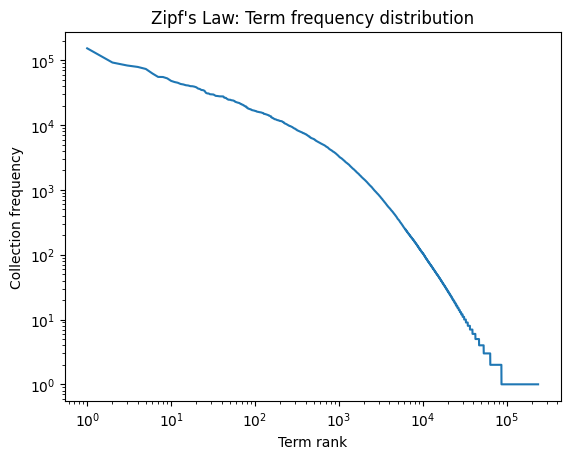

In [ ]:
# Extract term frequencies
term_freqs = []

for entry in lexicon:
    freq = entry.getValue().getFrequency()
    term_freqs.append(freq)

# Sort descending
term_freqs = sorted(term_freqs, reverse=True)
ranks = np.arange(1, len(term_freqs) + 1)


plt.figure()
plt.loglog(ranks, term_freqs)
plt.xlabel("Term rank")
plt.ylabel("Collection frequency")
plt.title("Zipf's Law: Term frequency distribution")
plt.show()


## Evaluation

Load dataframes with runs saved locally (optional, if the runs above were computed in a previous session of the same runtime)

In [ ]:
'''
run_bm25 = pd.read_csv(os.path.join(WORK_DIR, "run_bm25.csv"))
run_tfidf = pd.read_csv(os.path.join(WORK_DIR, "run_tfidf.csv"))
run_pl2 = pd.read_csv(os.path.join(WORK_DIR, "run_pl2.csv"))
run_dlh13 = pd.read_csv(RUN_DLH13_CSV)
run_dlh13_tc = pd.read_csv(os.path.join(WORK_DIR, "run_dlh13_tc.csv"))
run_dlh13_lem = pd.read_csv(os.path.join(WORK_DIR, "run_dlh13_lem.csv"))
run_dlh13_te_geo = pd.read_csv(os.path.join(WORK_DIR, "run_dlh13_te_geo.csv"))
run_dlh13_ne = pd.read_csv(os.path.join(WORK_DIR, "run_dlh13_ne.csv"))
'''

Run Experiments

In [ ]:
results = pt.Experiment(
    [run_tfidf, run_bm25, run_pl2, run_dlh13, run_dlh13_tc, run_dlh13_lem, run_dlh13_te_geo, run_dlh13_ne],
    queries_df,
    qrels_df,
    eval_metrics=[P@1, P@5, P@10, R@5, R@10, nDCG@5, nDCG@10, "map"],
    names=["TF_IDF", "BM25", "PL2", "DLH13", "DLH13_tc", "DLH13_lem", "DLH13_te_geo", "DLH13_ne"],
    verbose = True
)

pt.Experiment:   0%|          | 0/8 [00:00<?, ?system/s]

Visualize values for each algorithm and metric

In [ ]:
results = pd.DataFrame(results)
results.to_csv(os.path.join(WORK_DIR, "results_all.csv"), index = False)
display(results)

,name,map,P@1,P@5,P@10,R@5,R@10,nDCG@5,nDCG@10
0,TF_IDF,0.708384,0.6353,0.15916,0.08404,0.7958,0.8404,0.722311,0.736826
1,BM25,0.708274,0.6344,0.15916,0.08404,0.7958,0.8404,0.722170,0.736715
2,PL2,0.664803,0.5849,0.15186,0.08100,0.7593,0.8100,0.679390,0.695946
3,DLH13,0.719404,0.6480,0.16092,0.08492,0.8046,0.8492,0.733142,0.747660
4,DLH13_tc,0.592460,0.5126,0.13686,0.07429,0.6843,0.7429,0.605092,0.624104
5,DLH13_lem,0.708134,0.6357,0.15936,0.08411,0.7968,0.8411,0.722589,0.736969
6,DLH13_te_geo,0.715709,0.6443,0.16038,0.08479,0.8019,0.8479,0.729531,0.744515
7,DLH13_ne,0.726335,0.6560,0.16236,0.08514,0.8118,0.8514,0.740566,0.753493


# Phase 2: Preprocessing

Abbreviations used:

- ***tc***&nbsp;&nbsp;&nbsp;  -> Text Correction / Text Correction
- ***lem*** -> Lemmatization
- ***ner*** -> Named Entity Recognition
- ***te***&nbsp;&nbsp;&nbsp;  -> Temporal Expansion
- ***geo*** -> Geographical Expansion

The preprocessed version of the dataset is saved locally (in `WORK_DIR`). A ready-made copy is also loaded from Hugging Face in the following sections, so this part can be skipped.

In [ ]:
# (Google Drive is no longer used)

Mounted at /content/drive


Create dataframe for storing query processing results (Experimental part)

In [ ]:
queries_dataframe = pd.DataFrame(queries)

print(len(corpus_dataframe))
print(len(queries_dataframe))

131921
10000


## Text Cleaning/ OCR error correction
Approximate Execution time: 1.5 hours

In [ ]:
tqdm.pandas()

sym_spell = SymSpell(max_dictionary_edit_distance=2, prefix_length=7)

dictionary_path = pkg_resources.resource_filename(
    "symspellpy", "frequency_dictionary_en_82_765.txt")

if sym_spell.load_dictionary(dictionary_path, term_index=0, count_index=1):
    print("Dictionary loaded successfully.")
else:
    print("Failed to load dictionary. Please check the path or ensure the file exists.")

def correct_spelling_symspell(text):
    if not isinstance(text, str):
        return ""
    suggestions = sym_spell.lookup_compound(text,
                                          max_edit_distance=2,
                                          transfer_casing=True)
    if suggestions:
        return suggestions[0].term
    return text # Return original text if no suggestion found

corpus_dataframe['text_tc'] = corpus_dataframe['text'].progress_apply(correct_spelling_symspell)
display(corpus_dataframe.head())

Dictionary loaded successfully.


  0%|          | 0/131921 [00:00<?, ?it/s]

,docno,text,raw_ocr,publication_date,text_tc
0,New_Hampshire_18070804_1,Aiscellaneous Repository. From the Albany Regi...,fAiscellancous Bepogitory.\n. dvom the Albany ...,1807-08-04,Miscellaneous Repository fRom the aLbany rEgis...
1,New_Hampshire_18070804_4,Surely he above the rest of his fellow mortals...,Surely he a\nbove the rest of his fellow morta...,1807-08-04,Surely he above the rest of his fellow mortals...
2,New_Hampshire_18070804_5,"At Westmoreland, Mrs. Sally Lincoln, wife of M...","At Weltmoreland, Mrs. Sally Liacoln, wife\n~of...",1807-08-04,At Westmorland mrS salLy linColn wife of or sP...
3,New_Hampshire_18070804_8,Upon the correction of this remedy the stomach...,tion of this remedy the flomach is invariably\...,1807-08-04,Upon the correction of this remedy the stomach...
4,New_Hampshire_18070804_9,"Also FOR SALE AS ABOVE, NEW GOODS, STEPHEN HAR...","*°\n, ALSO POR SALE AS ABOVE,\no NEW-GEODS, -\...",1807-08-04,Also FOR SALE AS ABOVE NEW GOODS STEPHEN HARDY...


### Temporal Expansion - Support methods

In [ ]:
def get_pub_year(publication_date):
    return publication_date[:4] if publication_date else None

# It assumed that if the is a reference to a day and month
# but not a year, the year is the same as the one in
# the publication date.

def normalize_date(text, publication_date):
    pub_year = int(publication_date[:4])
    pub_month = int(publication_date[5:7])
    pub_day = int(publication_date[8:10])

    dt = dateparser.parse(
        text,
        settings={
            "STRICT_PARSING": False,
            "PREFER_DATES_FROM": "past",
            "RELATIVE_BASE": datetime(pub_year, pub_month, pub_day),  # stable anchor
            "RETURN_AS_TIMEZONE_AWARE": False,
        },
    )

    if not dt:
        return None

    # Case 1: explicit year in text
    if dt.month and dt.day and str(dt.year) in text:
        return dt.date().isoformat()

    # Case 2: month + day only -> inject publication year
    if dt.month and dt.day:
        return f"{pub_year}-{dt.month:02d}-{dt.day:02d}"

    return None

def normalize_date_query(text):

    dt = dateparser.parse(
        text,
        settings={
            "STRICT_PARSING": False,
            "PREFER_DATES_FROM": "past",
            "RETURN_AS_TIMEZONE_AWARE": False,
        },
    )

    if not dt:
        return None

    # Case 1: explicit year in text
    if dt.month and dt.day and str(dt.year) in text:
        return dt.date().isoformat()

    # Case 2: month + day only → inject publication year
    if dt.month and dt.day:
        return f"{"0000"}-{dt.month:02d}-{dt.day:02d}"

    # Case (Exception)
    if dt.year and dt.month:
        return f"{dt.year}-{dt.month:02d}-{"0000"}"

    # Case (Exception)
    if dt.year and dt.day:
        return f"{dt.year}-{"0000"}-{dt.day:02d}"

    return None


### Lemmatization, NER, Temporal Expansion, Geographic Expansion

In [ ]:
nlp = spacy.load(
    "en_core_web_sm",
    disable=["parser"]  # keep tagger, lemmatizer, ner
)

def process_texts(texts, publication_dates=None):
    results = []

    for i, doc in enumerate(tqdm(nlp.pipe(texts, batch_size=128), total=len(texts))):
        item = {}

        # -------- Lemmatization --------
        item["lemmas"] = " ".join(
            token.lemma_.lower()
            for token in doc
            if not token.is_punct and not token.is_space
        )

        # -------- Named Entities --------
        item["named_entities"] = [ent.text for ent in doc.ents]

        # -------- Temporal --------
        dates = []
        pub_date = publication_dates[i] if publication_dates is not None else None

        for ent in doc.ents:
            if ent.label_ == "DATE":
                norm = (
                    normalize_date(ent.text, pub_date)
                    if pub_date
                    else normalize_date_query(ent.text)
                )
                if norm:
                    dates.append(norm)

        item["normalized_dates"] = sorted(set(dates))

        # -------- Geographical --------
        item["locations_text"] = sorted({
            ent.text
            for ent in doc.ents
            if ent.label_ in ("GPE", "LOC", "FAC")
        })

        results.append(item)

    return results


### Apply results to documents

In [ ]:
corpus_results = process_texts(
    corpus_dataframe["text"].astype(str).tolist(),
    corpus_dataframe["publication_date"].astype(str).tolist(),
)

corpus_dataframe["text_tc_lem"] = [r["lemmas"] for r in corpus_results]
corpus_dataframe["named_entities"] = [r["named_entities"] for r in corpus_results]
corpus_dataframe["normalized_dates"] = [r["normalized_dates"] for r in corpus_results]
corpus_dataframe["locations_text"] = [r["locations_text"] for r in corpus_results]


100%|██████████| 131921/131921 [2:24:32<00:00, 15.21it/s]


### Apply results to queries

In [ ]:
query_results = process_texts(
    queries_dataframe["question"].astype(str).tolist()
)

queries_dataframe["question_lemmatized"] = [r["lemmas"] for r in query_results]
queries_dataframe["named_entities"] = [r["named_entities"] for r in query_results]
queries_dataframe["normalized_dates"] = [r["normalized_dates"] for r in query_results]
queries_dataframe["locations_text"] = [r["locations_text"] for r in query_results]


100%|██████████| 10000/10000 [00:34<00:00, 286.65it/s]


Count rows containing at least one date

In [ ]:
non_empty_dates_count = corpus_dataframe[corpus_dataframe['normalized_dates'].apply(lambda x: len(x) > 0)].shape[0]
print(f"Number of rows with non-empty normalized_dates: {non_empty_dates_count}")

corpus_dataframe.head(10)

Number of rows with non-empty normalized_dates: 90873


,docno,text,raw_ocr,publication_date,text_tc,text_tc_lem,named_entities,normalized_dates,locations_text
0,New_Hampshire_18070804_1,Aiscellaneous Repository. From the Albany Regi...,fAiscellancous Bepogitory.\n. dvom the Albany ...,1807-08-04,Miscellaneous Repository fRom the aLbany rEgis...,aiscellaneous repository from the albany regis...,"[the Albany Register, WAR, British Outrage, Ho...",[],"[Tripoli, War]"
1,New_Hampshire_18070804_4,Surely he above the rest of his fellow mortals...,Surely he a\nbove the rest of his fellow morta...,1807-08-04,Surely he above the rest of his fellow mortals...,surely he above the rest of his fellow mortal ...,"[France, de Rosemberg, 83, France, the Legion ...","[1807-02-04, 1807-08-04]","[Andover, Baltimore, Brunswick, Chesterfield, ..."
2,New_Hampshire_18070804_5,"At Westmoreland, Mrs. Sally Lincoln, wife of M...","At Weltmoreland, Mrs. Sally Liacoln, wife\n~of...",1807-08-04,At Westmorland mrS salLy linColn wife of or sP...,at westmoreland mrs. sally lincoln wife of mr....,"[Westmoreland, Sally Lincoln, Spencer L., 28, ...","[1807-07-28, 1807-08-01, 1807-08-28]","[Henrico, NEW GONDOLA, New Hampshire Fire]"
3,New_Hampshire_18070804_8,Upon the correction of this remedy the stomach...,tion of this remedy the flomach is invariably\...,1807-08-04,Upon the correction of this remedy the stomach...,upon the correction of this remedy the stomach...,"[Bitters, Newbury Street, Winter Street, Bosto...",[],"[Boston, New England, Newbury Street, Winter S..."
4,New_Hampshire_18070804_9,"Also FOR SALE AS ABOVE, NEW GOODS, STEPHEN HAR...","*°\n, ALSO POR SALE AS ABOVE,\no NEW-GEODS, -\...",1807-08-04,Also FOR SALE AS ABOVE NEW GOODS STEPHEN HARDY...,also for sale as above new goods stephen hardy...,"[NEW GOODS, STEPHEN HARDY, Market Street, JEWE...",[],"[Market Street, NEW GOODS, Trays]"
5,New_Hampshire_18070804_13,At a meeting of the committee of the : subscri...,At a meeting of the committee of the\n: fcﬁjcr...,1807-08-04,At a meeting of the committee of the subscript...,at a meeting of the committee of the subscript...,"[St John's, Monday the 27th of July, 1807, thi...","[1807-07-21, 1807-07-27, 1807-07-28]","[Panama, Portsmouth]"
6,New_Hampshire_18070804_14,Notice is hereby given to the proprietors of t...,N OTICE is hereby given to these propri-\nX et...,1807-08-04,Notice is hereby given to the proprietors of t...,notice be hereby give to the proprietor of the...,"[Notice, the Fourth Turnpike Road, New Hampshi...","[1807-08-04, 1807-08-22, 1807-08-30]","[New Hampshire, Springfield, Turnpike Road, th..."
7,New_Hampshire_18070804_16,"‘ . LO, L, George Frost, Esq. X 30 I 14 2 1 3 ...","‘ . LO, L,\nGegrge Frofl, Efg. X 30 ‘I 14 2 1 ...",1807-08-04,low George Frost Esq a of i of a a a a tHeodor...,lo l george frost esq x 30 i 14 2 1 3 3 theodo...,"[LO, L, George Frost, Esq, Theodore Lyman, Dit...","[1807-02-04, 1807-02-25, 1807-04-04, 1807-04-2...","[Ditto, Esq, Inquire of W. Bowles, L]"
8,New_Hampshire_18070804_18,Swedes do. 150 bbls. fresh FLOUR. MOLASSES and...,Swedes do.\n 150 bbls. freth FLOUR.\n MOI.ASSE...,1807-08-04,Swedes do a of bbl fresh flOUR MolASSES ANd ru...,swede do 150 bbls fresh flour molasse and rum ...,"[Swedes, 150, FLOUR, RUM, Figs, 1, BEEF, Ports...","[1807-07-21, 1807-07-28]","[New-Hampshire, Portsmouth, the Subscriber on ..."
9,New_Hampshire_18060715_1,The Portsmouthaathinna in the Miscellaneous Re...,P tsmnatahiniinni il\nz Miscellaneous Reposito...,1806-07-15,The Portsmouth think in the miScellaneous rePo...,the portsmouthaathinna in the miscellaneous re...,"[the Miscellaneous Repository, ODE, American I...",[1806-07-04],"[Portsmouth, Trusting, the Miscellaneous Repos..."


In [ ]:
non_empty_dates_count = queries_dataframe[queries_dataframe['normalized_dates'].apply(lambda x: len(x) > 0)].shape[0]
print(f"Number of rows with non-empty normalized_dates: {non_empty_dates_count}")

queries_dataframe.head(100)

Number of rows with non-empty normalized_dates: 659


,query_id,question,question_lemmatized,named_entities,normalized_dates,locations_text
0,test_1,How many lots did Thomas Peirce have,how many lot do thomas peirce have,[Thomas Peirce],[],[]
1,test_10,Who gave Hamilton the substance of what he had...,who give hamilton the substance of what he hav...,"[Hamilton, Hamilton]",[],[]
2,test_100,Who informs his FRIENDS and the PUBLIC that he...,who inform his friend and the public that he h...,"[FRIENDS, INN]",[],[]
3,test_1000,Who was the Secretary of the Treasury of the U...,who be the secretary of the treasury of the un...,"[Treasury, the United States]",[],[the United States]
4,test_10000,Who made a speech in front of the Brooks House,who make a speech in front of the brooks house,[the Brooks House],[],[]
...,...,...,...,...,...,...
95,test_10083,Who was the director of SWAN CO S LOTTERIES,who be the director of swan co s lottery,[SWAN CO S LOTTERIES],[],[]
96,test_10084,What was the number of the r aei r of Nip,what be the number of the r aei r of nip,[Nip],[],[]
97,test_10085,What was 9 5 cts of pickled hams,what be 9 5 ct of pickle ham,[9 5 cts],[],[]
98,test_10086,Who was a Senator elect from the State of Loui...,who be a senator elect from the state of louis...,"[the State of Louisiana, six years, March 04 1...","[0000-12-28, 1859-03-04]",[the State of Louisiana]


Example of a document containing date without the year specified

In [ ]:
print(corpus_dataframe.iloc[2]["text_tc_lem"])

at westmoreland mrs. sally lincoln wife of mr. spencer l. age 28 at henrico mrs. polly adams consort on saturday the 11th ult mr. joseph meyer of hampstead be find dead in the road his horse stand by he when oy e g e smith rust pocket book lost lose last wednesday between 7 and 8 o’clock in the afternoon either in the globe tavern at the plains or on the road lead from thence to portsmouth a new red morocco pocket book contain some money notes of hand payable to the subscriber also new hampshire fire and marine certificates and other paper valuable to none but to the owner whoever shall find say pocket book and re- turn it with its content with or without the money shall be handsomely reward and the thank of their humble servant edward parry to be let that fireproof store lately improve by mr. benjamin swett which must be allow to be the good stand for business either for english or west- india goods in this town inquire of edward parry who have a large assortment of the fashionable go

Store the preprocessed dataset

In [ ]:
corpus_dataframe.to_json(CORPUS_PREPROCESSED_LOCAL)

In [ ]:
queries_dataframe.to_json(QUERIES_PREPROCESSED_LOCAL)

# Phase 2: First Stage Retrieval

### Preparation of Documents

In [ ]:
# Prepare dataframe for PyTerrier: needs columns 'docno' and 'text'
corpus_dataframe_preprocessed = load_corpus_preprocessed()
corpus_dataframe_preprocessed = corpus_dataframe_preprocessed.rename(columns={"para_id": "docno", "context": "text"})
corpus_dataframe_preprocessed.head()

,docno,text,raw_ocr,publication_date,text_tc,text_tc_lem,named_entities,normalized_dates,locations_text
0,New_Hampshire_18070804_1,Aiscellaneous Repository. From the Albany Regi...,fAiscellancous Bepogitory.\n. dvom the Albany ...,1807-08-04,Miscellaneous Repository fRom the aLbany rEgis...,aiscellaneous repository from the albany regis...,"[the Albany Register, WAR, British Outrage, Ho...",[],"[Tripoli, War]"
1,New_Hampshire_18070804_4,Surely he above the rest of his fellow mortals...,Surely he a\nbove the rest of his fellow morta...,1807-08-04,Surely he above the rest of his fellow mortals...,surely he above the rest of his fellow mortal ...,"[France, de Rosemberg, 83, France, the Legion ...","[1807-02-04, 1807-08-04]","[Andover, Baltimore, Brunswick, Chesterfield, ..."
2,New_Hampshire_18070804_5,"At Westmoreland, Mrs. Sally Lincoln, wife of M...","At Weltmoreland, Mrs. Sally Liacoln, wife\n~of...",1807-08-04,At Westmorland mrS salLy linColn wife of or sP...,at westmoreland mrs. sally lincoln wife of mr....,"[Westmoreland, Sally Lincoln, Spencer L., 28, ...","[1807-07-28, 1807-08-01, 1807-08-28]","[Henrico, NEW GONDOLA, New Hampshire Fire]"
3,New_Hampshire_18070804_8,Upon the correction of this remedy the stomach...,tion of this remedy the flomach is invariably\...,1807-08-04,Upon the correction of this remedy the stomach...,upon the correction of this remedy the stomach...,"[Bitters, Newbury Street, Winter Street, Bosto...",[],"[Boston, New England, Newbury Street, Winter S..."
4,New_Hampshire_18070804_9,"Also FOR SALE AS ABOVE, NEW GOODS, STEPHEN HAR...","*°\n, ALSO POR SALE AS ABOVE,\no NEW-GEODS, -\...",1807-08-04,Also FOR SALE AS ABOVE NEW GOODS STEPHEN HARDY...,also for sale as above new goods stephen hardy...,"[NEW GOODS, STEPHEN HARDY, Market Street, JEWE...",[],"[Market Street, NEW GOODS, Trays]"


### Indexing

In [ ]:
index = load_or_build_terrier_index(
    "timeRetrieval_index", "text",
    lambda: corpus_dataframe.to_dict(orient="records"))

Index loaded from disk.


### Index Statistics

In [ ]:
stats = index.getCollectionStatistics()

print("Terrier Collection Statistics")
print("--------------------------------")
print(f"Indexed documents:        {stats.getNumberOfDocuments()}")
print(f"Unique terms (vocabulary): {stats.getNumberOfUniqueTerms()}")
print(f"Total tokens:             {stats.getNumberOfTokens()}")
print(f"Average document length:  {stats.getAverageDocumentLength():.2f}")

Terrier Collection Statistics
--------------------------------
Indexed documents:        131921
Unique terms (vocabulary): 236646
Total tokens:             15575099
Average document length:  118.06


### Preparation of Qrels and Queries

In [ ]:
# Convert qrels to a Dataframe with only "qid", "docno" and "label" columns
qrels_df = pd.DataFrame(qrels).rename(columns={'query_id': 'qid', 'para_id': 'docno', 'relevance': 'label'})[['qid', 'docno', 'label']]

# Convert queries to a DataFrame with "qid" and "query" columns
queries_df = pd.DataFrame(queries).rename(columns={'query_id': 'qid', 'question': 'query'})[['qid', 'query']]

### Retrieval

In [ ]:
# ---- Method 1 ----
# Run DLH13 on all queries
'''
dlh13 = pt.terrier.Retriever(index, wmodel="DLH13", verbose = True)
run_dlh13  = dlh13.transform(queries_df)

# Store the results
run_dlh13.to_csv(os.path.join(WORK_DIR, "run_dlh13_preprocessed.csv"), index=False)
'''

# ---- Method 2 ----
# Load the results of the run performed in Phase 1 (computed now if not available)
run_dlh13 = get_run_dlh13(queries_df)

### Evaluation of the First Stage

In [ ]:
results = pt.Experiment(
    [run_dlh13],
    queries_df,
    qrels_df,
    eval_metrics=[P@1, P@5, P@10, R@5, R@10, nDCG@5, nDCG@10, "map"],
    names=["DLH13"],
    verbose = True
)

pt.Experiment:   0%|          | 0/1 [00:00<?, ?system/s]

In [ ]:
results = pd.DataFrame(results)
display(results)

,name,map,P@1,P@5,P@10,R@5,R@10,nDCG@5,nDCG@10
0,DLH13,0.719404,0.648,0.16092,0.08492,0.8046,0.8492,0.733142,0.74766


# Phase 2: Second Stage Retrieval

Implementation based on these GitHub pages

- https://github.com/terrierteam/pyterrier_dr

- https://github.com/terrierteam/pyterrier_dr/blob/main/pyterrier_dr/sbert_models.py

- https://github.com/terrierteam/pyterrier_dr/blob/main/pyterrier_dr/biencoder.py


Relevant PyTerrier source

- https://pyterrier.readthedocs.io/en/latest/pipeline_examples.html

Initialization used for tests consucted sepatately for the Second Stage Retrieval

In [ ]:
corpus_dataframe_preprocessed = load_corpus_preprocessed()
corpus_dataframe_preprocessed = corpus_dataframe_preprocessed.rename(columns={"para_id": "docno", "context": "text"})
qrels_df = pd.DataFrame(qrels).rename(columns={'query_id': 'qid', 'para_id': 'docno', 'relevance': 'label'})[['qid', 'docno', 'label']]
queries_df = pd.DataFrame(queries).rename(columns={'query_id': 'qid', 'question': 'query'})[['qid', 'query']]

run_dlh13 = get_run_dlh13(queries_df)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Merge the results of DLH13 and the original preprocessed corpus

In [ ]:
run_dlh13 = run_dlh13.merge(corpus_dataframe_preprocessed[["docno", "text"]], on="docno", how="inner")

## Bi-Encoder Reranker 1: all-MiniLM-L6-v2

In [ ]:
sentence_model = SBertBiEncoder('sentence-transformers/all-MiniLM-L6-v2', device = "cuda")

### Indexing

In [ ]:
index_path = dense_index_path("all-MiniLM-L6-v2_index")

dense_index = FlexIndex(index_path)

if os.path.exists(index_path) and os.listdir(index_path):
    dense_index.load(index_path)
    print("Index loaded from disk.")
else:
    os.makedirs(index_path, exist_ok=True)

    index_pipeline = sentence_model >> dense_index.indexer(mode="overwrite")
    index_pipeline.index(
        tqdm(
            corpus_dataframe_preprocessed.to_dict("records"),
            total=len(corpus_dataframe_preprocessed)
        )
    )
    print("Index created and saved.")

Index loaded from disk.


In [ ]:
index_pipeline

(SBertBiEncoder('sentence-transformers/all-MiniLM-L6-v2') >> FlexIndex('/content/drive/MyDrive/projectIR/projectIR/all-MiniLM-L6-v2_index').indexer(mode=<IndexingMode.overwrite: 'overwrite'>))

### Approach 1: Re-Ranker only

In [ ]:
retrieval_pipeline = (
    pt.Transformer.from_df(run_dlh13) % 50 >>
    sentence_model.query_encoder() >>
    dense_index.scorer()
)

pt.Experiment(
    [retrieval_pipeline],
    queries_df,
    qrels_df,
    eval_metrics=[P@1, P@5, P@10, R@5, R@10, nDCG@5, nDCG@10, "map"],
    names=["Re-Ranker only"],
    verbose = True
)

0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/pyterrier/_evaluation/_validation.py:76: UserWarning: Experiment Pipeline Validation Report

The following pipelines could not be validated (i.e., it is unclear what outputs they produce):
 - Pipeline #0: retrieval pipeline ((<pyterrier.transformer.SourceTransformer object at 0x7f230e167f20> >> RankCutoff(50) >> SBertBiEncoder('sentence-transformers/all-MiniLM-L6-v2').query_encoder() >> <pyterrier_dr.flex.np_retr.NumpyScorer object at 0x7f230e1a4770>))
If these pipelines work, set validate='ignore' to remove this warning, or make them inspectable to clarify how they work.

See https://pyterrier.readthedocs.io/en/latest/troubleshooting/inspection.html for more information.
  warn(message)


pt.Experiment:   0%|          | 0/1 [00:00<?, ?system/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

,name,map,P@1,P@5,P@10,R@5,R@10,nDCG@5,nDCG@10
0,retrieval pipeline,0.390689,0.2808,0.09968,0.06097,0.4984,0.6097,0.395539,0.431416


In [ ]:
retrieval_pipeline

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

(<pyterrier.transformer.SourceTransformer object at 0x7f231575a540> >> RankCutoff(50) >> SBertBiEncoder('sentence-transformers/all-MiniLM-L6-v2').query_encoder() >> <pyterrier_dr.flex.np_retr.NumpyScorer object at 0x7f2315747020>)

### Approach 2: Combination DLH + Re-Ranker (Empirically Set Weights)

In [ ]:
retrieval_pipeline_combined = (
    pt.Transformer.from_df(run_dlh13) % 50 >>
      ( 0.1 * pt.Transformer.identity() +
        0.9 * (sentence_model.query_encoder() >> dense_index.scorer())
      )
    )

pt.Experiment(
    [retrieval_pipeline_combined],
    queries_df,
    qrels_df,
    eval_metrics=[P@1, P@5, P@10, R@5, R@10, nDCG@5, nDCG@10, "map"],
    names=["Empirically Set Weights"],
    verbose = True
)

0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/pyterrier/_evaluation/_validation.py:76: UserWarning: Experiment Pipeline Validation Report

The following pipelines could not be validated (i.e., it is unclear what outputs they produce):
 - Pipeline #0: retrieval pipeline ((<pyterrier.transformer.SourceTransformer object at 0x7f23157440e0> >> RankCutoff(50) >> <pyterrier._ops.Sum object at 0x7f23157c9f10>))
If these pipelines work, set validate='ignore' to remove this warning, or make them inspectable to clarify how they work.

See https://pyterrier.readthedocs.io/en/latest/troubleshooting/inspection.html for more information.
  warn(message)


pt.Experiment:   0%|          | 0/1 [00:00<?, ?system/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

,name,map,P@1,P@5,P@10,R@5,R@10,nDCG@5,nDCG@10
0,retrieval pipeline,0.719042,0.6469,0.1609,0.08527,0.8045,0.8527,0.732948,0.748669


In [ ]:
retrieval_pipeline_combined

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

(<pyterrier.transformer.SourceTransformer object at 0x7f23157440e0> >> RankCutoff(50) >> <pyterrier._ops.Sum object at 0x7f23157c9f10>)

### Approach 3: Combination DLH + Re-Ranker (RRF)

In [ ]:
import pyterrier_alpha as pta

lexical_run = pt.Transformer.from_df(run_dlh13)
dense_scorer = sentence_model.query_encoder() >> dense_index.scorer()

fused_pipeline = (lexical_run % 50) >> pta.RRFusion(
    pt.Transformer.identity(),
    dense_scorer,
    k=40
)

pt.Experiment(
    [fused_pipeline],
    queries_df,
    qrels_df,
    eval_metrics=[P@1, P@5, P@10, R@5, R@10, nDCG@5, nDCG@10, "map"],
    names=["RRF"],
    verbose=True
)

0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/pyterrier/_evaluation/_validation.py:76: UserWarning: Experiment Pipeline Validation Report

The following pipelines could not be validated (i.e., it is unclear what outputs they produce):
 - Pipeline #0: RRF Fusion Pipeline ((<pyterrier.transformer.SourceTransformer object at 0x7f2318acc0e0> >> RankCutoff(50) >> <pyterrier_alpha.fusion.RRFusion object at 0x7f2318a483b0>))
If these pipelines work, set validate='ignore' to remove this warning, or make them inspectable to clarify how they work.

See https://pyterrier.readthedocs.io/en/latest/troubleshooting/inspection.html for more information.
  warn(message)


pt.Experiment:   0%|          | 0/1 [00:00<?, ?system/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

,name,map,P@1,P@5,P@10,R@5,R@10,nDCG@5,nDCG@10
0,RRF Fusion Pipeline,0.55619,0.4429,0.13766,0.08043,0.6883,0.8043,0.57204,0.609629


In [ ]:
fused_pipeline

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

(<pyterrier.transformer.SourceTransformer object at 0x7f2318acc0e0> >> RankCutoff(50) >> <pyterrier_alpha.fusion.RRFusion object at 0x7f2318a483b0>)

### Approach 4: Combination DLH + Re-Ranker (Normalization)

In [ ]:
def min_max_by_query(df):
    if df.empty: return df

    def norm(group):
        max_s = group['score'].max()
        min_s = group['score'].min()
        if max_s - min_s > 0:
            group['score'] = (group['score'] - min_s) / (max_s - min_s)
        else:
            group['score'] = 1.0 # Default if all scores are identical
        return group

    return df.groupby('qid', group_keys=False).apply(norm)

norm = pt.apply.generic(min_max_by_query)

retrieval_pipeline_normalized = (
    pt.Transformer.from_df(run_dlh13) % 50 >> (
        0.9 * (pt.Transformer.identity() >> norm) +
        0.1 * (sentence_model.query_encoder() >> dense_index.scorer() >> norm)
    )
)

pt.Experiment(
    [retrieval_pipeline_normalized],
    queries_df,
    qrels_df,
    eval_metrics=[P@1, P@5, P@10, R@5, R@10, nDCG@5, nDCG@10, "map"],
    names=["Normalized Scores"],
    verbose=True
)

0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/pyterrier/_evaluation/_validation.py:76: UserWarning: Experiment Pipeline Validation Report

The following pipelines could not be validated (i.e., it is unclear what outputs they produce):
 - Pipeline #0: Normalized Pipeline ((<pyterrier.transformer.SourceTransformer object at 0x7f231572ae70> >> RankCutoff(50) >> <pyterrier._ops.Sum object at 0x7f231cc357f0>))
If these pipelines work, set validate='ignore' to remove this warning, or make them inspectable to clarify how they work.

See https://pyterrier.readthedocs.io/en/latest/troubleshooting/inspection.html for more information.
  warn(message)


pt.Experiment:   0%|          | 0/1 [00:00<?, ?system/s]

/tmp/ipython-input-953143308.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby('qid', group_keys=False).apply(norm)


  0%|          | 0/10000 [00:00<?, ?it/s]

/tmp/ipython-input-953143308.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby('qid', group_keys=False).apply(norm)


,name,map,P@1,P@5,P@10,R@5,R@10,nDCG@5,nDCG@10
0,Normalized Pipeline,0.720104,0.6484,0.16126,0.0852,0.8063,0.852,0.73449,0.749312


In [ ]:
retrieval_pipeline_normalized

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

(<pyterrier.transformer.SourceTransformer object at 0x7f231572ae70> >> RankCutoff(50) >> <pyterrier._ops.Sum object at 0x7f231cc357f0>)

## Bi-Encoder Reranker 2: snowflake-arctic-embed-xs

In [ ]:
sentence_model2 = SBertBiEncoder('Snowflake/snowflake-arctic-embed-xs', device = "cuda")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/107 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/737 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.3M [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

### Indexing

In [ ]:
index_path = dense_index_path("snowflake-arctic-embed-xs_index")

dense_index = FlexIndex(index_path)

if os.path.exists(index_path) and os.listdir(index_path):
    dense_index.load(index_path)
    print("Index loaded from disk.")
else:
    os.makedirs(index_path, exist_ok=True)

    index_pipeline = sentence_model2 >> dense_index.indexer(mode="overwrite")
    index_pipeline.index(
        tqdm(
            corpus_dataframe_preprocessed.to_dict("records"),
            total=len(corpus_dataframe_preprocessed)
        )
    )
    print("Index created and saved.")

Index loaded from disk.


### Approach 1: Re-Ranker only

In [ ]:
retrieval_pipeline = (
    pt.Transformer.from_df(run_dlh13) % 50 >>
    sentence_model2.query_encoder() >>
    dense_index.scorer()
)

pt.Experiment(
    [retrieval_pipeline],
    queries_df,
    qrels_df,
    eval_metrics=[P@1, P@5, P@10, R@5, R@10, nDCG@5, nDCG@10, "map"],
    names=["Re-Ranker only"],
    verbose = True
)

0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/pyterrier/_evaluation/_validation.py:76: UserWarning: Experiment Pipeline Validation Report

The following pipelines could not be validated (i.e., it is unclear what outputs they produce):
 - Pipeline #0: Re-Ranker only ((<pyterrier.transformer.SourceTransformer object at 0x7f231e240380> >> RankCutoff(50) >> SBertBiEncoder('Snowflake/snowflake-arctic-embed-xs').query_encoder() >> <pyterrier_dr.flex.np_retr.NumpyScorer object at 0x7f231a0ba540>))
If these pipelines work, set validate='ignore' to remove this warning, or make them inspectable to clarify how they work.

See https://pyterrier.readthedocs.io/en/latest/troubleshooting/inspection.html for more information.
  warn(message)


pt.Experiment:   0%|          | 0/1 [00:00<?, ?system/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

,name,map,P@1,P@5,P@10,R@5,R@10,nDCG@5,nDCG@10
0,Re-Ranker only,0.3598,0.2463,0.09408,0.05954,0.4704,0.5954,0.362743,0.403107


In [ ]:
retrieval_pipeline

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

(<pyterrier.transformer.SourceTransformer object at 0x7f231e240380> >> RankCutoff(50) >> SBertBiEncoder('Snowflake/snowflake-arctic-embed-xs').query_encoder() >> <pyterrier_dr.flex.np_retr.NumpyScorer object at 0x7f231a0ba540>)

### Approach 2: Combination DLH + Re-Ranker (Empirically Set Weights)

In [ ]:
retrieval_pipeline_combined = (
    pt.Transformer.from_df(run_dlh13) % 30 >>
      ( 0.1 * pt.Transformer.identity() +
        0.9 * (sentence_model2.query_encoder() >> dense_index.scorer())
      )
    )

pt.Experiment(
    [retrieval_pipeline_combined],
    queries_df,
    qrels_df,
    eval_metrics=[P@1, P@5, P@10, R@5, R@10, nDCG@5, nDCG@10, "map"],
    names=["Empirically Set Weights"],
    verbose = True
)

0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/pyterrier/_evaluation/_validation.py:76: UserWarning: Experiment Pipeline Validation Report

The following pipelines could not be validated (i.e., it is unclear what outputs they produce):
 - Pipeline #0: Empirically Set Weights ((<pyterrier.transformer.SourceTransformer object at 0x7f2314cf2540> >> RankCutoff(30) >> <pyterrier._ops.Sum object at 0x7f230fbef8f0>))
If these pipelines work, set validate='ignore' to remove this warning, or make them inspectable to clarify how they work.

See https://pyterrier.readthedocs.io/en/latest/troubleshooting/inspection.html for more information.
  warn(message)


pt.Experiment:   0%|          | 0/1 [00:00<?, ?system/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

,name,map,P@1,P@5,P@10,R@5,R@10,nDCG@5,nDCG@10
0,Empirically Set Weights,0.724658,0.6543,0.1621,0.08542,0.8105,0.8542,0.739602,0.75378


In [ ]:
retrieval_pipeline_combined

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

(<pyterrier.transformer.SourceTransformer object at 0x7f2314cf2540> >> RankCutoff(30) >> <pyterrier._ops.Sum object at 0x7f230fbef8f0>)

### Approach 3: Combination DLH + Re-Ranker (RRF)

In [ ]:
import pyterrier_alpha as pta

lexical_run = pt.Transformer.from_df(run_dlh13)
dense_scorer = sentence_model2.query_encoder() >> dense_index.scorer()

fused_pipeline = (lexical_run % 50) >> pta.RRFusion(
    pt.Transformer.identity(),
    dense_scorer,
    k=40
)

pt.Experiment(
    [fused_pipeline],
    queries_df,
    qrels_df,
    eval_metrics=[P@1, P@5, P@10, R@5, R@10, nDCG@5, nDCG@10, "map"],
    names=["RRF"],
    verbose=True
)

0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/pyterrier/_evaluation/_validation.py:76: UserWarning: Experiment Pipeline Validation Report

The following pipelines could not be validated (i.e., it is unclear what outputs they produce):
 - Pipeline #0: RRF ((<pyterrier.transformer.SourceTransformer object at 0x7f230e400d40> >> RankCutoff(50) >> <pyterrier_alpha.fusion.RRFusion object at 0x7f230f3de090>))
If these pipelines work, set validate='ignore' to remove this warning, or make them inspectable to clarify how they work.

See https://pyterrier.readthedocs.io/en/latest/troubleshooting/inspection.html for more information.
  warn(message)


pt.Experiment:   0%|          | 0/1 [00:00<?, ?system/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

,name,map,P@1,P@5,P@10,R@5,R@10,nDCG@5,nDCG@10
0,RRF,0.559364,0.439,0.1408,0.08161,0.704,0.8161,0.579295,0.615627


In [ ]:
fused_pipeline

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

(<pyterrier.transformer.SourceTransformer object at 0x7f230e400d40> >> RankCutoff(50) >> <pyterrier_alpha.fusion.RRFusion object at 0x7f230f3de090>)

### Approach 4: Combination DLH + Re-Ranker (Normalization)

In [ ]:
def min_max_by_query(df):
    if df.empty: return df

    def norm(group):
        max_s = group['score'].max()
        min_s = group['score'].min()
        if max_s - min_s > 0:
            group['score'] = (group['score'] - min_s) / (max_s - min_s)
        else:
            group['score'] = 1.0 # Default if all scores are identical
        return group

    return df.groupby('qid', group_keys=False).apply(norm)

norm = pt.apply.generic(min_max_by_query)

retrieval_pipeline_normalized = (
    pt.Transformer.from_df(run_dlh13) % 50 >> (
        0.9 * (pt.Transformer.identity() >> norm) +
        0.1 * (sentence_model2.query_encoder() >> dense_index.scorer() >> norm)
    )
)

pt.Experiment(
    [retrieval_pipeline_normalized],
    queries_df,
    qrels_df,
    eval_metrics=[P@1, P@5, P@10, R@5, R@10, nDCG@5, nDCG@10, "map"],
    names=["Normalized Scores"],
    verbose=True
)

0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/pyterrier/_evaluation/_validation.py:76: UserWarning: Experiment Pipeline Validation Report

The following pipelines could not be validated (i.e., it is unclear what outputs they produce):
 - Pipeline #0: Normalized Scores ((<pyterrier.transformer.SourceTransformer object at 0x7f231d970590> >> RankCutoff(50) >> <pyterrier._ops.Sum object at 0x7f23206637a0>))
If these pipelines work, set validate='ignore' to remove this warning, or make them inspectable to clarify how they work.

See https://pyterrier.readthedocs.io/en/latest/troubleshooting/inspection.html for more information.
  warn(message)


pt.Experiment:   0%|          | 0/1 [00:00<?, ?system/s]

/tmp/ipython-input-3401914699.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby('qid', group_keys=False).apply(norm)


  0%|          | 0/10000 [00:00<?, ?it/s]

/tmp/ipython-input-3401914699.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby('qid', group_keys=False).apply(norm)


,name,map,P@1,P@5,P@10,R@5,R@10,nDCG@5,nDCG@10
0,Normalized Scores,0.722647,0.6518,0.1616,0.08514,0.808,0.8514,0.736974,0.751061


In [ ]:
retrieval_pipeline_normalized

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

(<pyterrier.transformer.SourceTransformer object at 0x7f231d970590> >> RankCutoff(50) >> <pyterrier._ops.Sum object at 0x7f23206637a0>)

## Bi-Encoder Reranker 3: BGE-Reranker-Base


In [ ]:
sentence_model3 = SBertBiEncoder('BAAI/bge-base-en-v1.5', device = "cuda")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

### Indexing

In [ ]:
index_path = dense_index_path("bge-base-en-v1.5_index")

dense_index = FlexIndex(index_path)

if os.path.exists(index_path) and os.listdir(index_path):
    dense_index.load(index_path)
    print("Index loaded from disk.")
else:
    os.makedirs(index_path, exist_ok=True)

    index_pipeline = sentence_model3 >> dense_index.indexer(mode="overwrite")
    index_pipeline.index(
        tqdm(
            corpus_dataframe_preprocessed.to_dict("records"),
            total=len(corpus_dataframe_preprocessed)
        )
    )
    print("Index created and saved.")

Index loaded from disk.


### Approach 1: Re-Ranker only

In [ ]:
retrieval_pipeline = (
    pt.Transformer.from_df(run_dlh13) % 50 >>
    sentence_model3.query_encoder() >>
    dense_index.scorer()
)

pt.Experiment(
    [retrieval_pipeline],
    queries_df,
    qrels_df,
    eval_metrics=[P@1, P@5, P@10, R@5, R@10, nDCG@5, nDCG@10, "map"],
    names=["Re-Ranker only"],
    verbose = True
)

0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/pyterrier/_evaluation/_validation.py:76: UserWarning: Experiment Pipeline Validation Report

The following pipelines could not be validated (i.e., it is unclear what outputs they produce):
 - Pipeline #0: Re-Ranker only ((<pyterrier.transformer.SourceTransformer object at 0x7f230f582a20> >> RankCutoff(50) >> SBertBiEncoder('BAAI/bge-base-en-v1.5').query_encoder() >> <pyterrier_dr.flex.np_retr.NumpyScorer object at 0x7f230f580230>))
If these pipelines work, set validate='ignore' to remove this warning, or make them inspectable to clarify how they work.

See https://pyterrier.readthedocs.io/en/latest/troubleshooting/inspection.html for more information.
  warn(message)


pt.Experiment:   0%|          | 0/1 [00:00<?, ?system/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

,name,map,P@1,P@5,P@10,R@5,R@10,nDCG@5,nDCG@10
0,Re-Ranker only,0.438262,0.3314,0.10962,0.06468,0.5481,0.6468,0.445853,0.477838


In [ ]:
retrieval_pipeline

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

(<pyterrier.transformer.SourceTransformer object at 0x7f230f582a20> >> RankCutoff(50) >> SBertBiEncoder('BAAI/bge-base-en-v1.5').query_encoder() >> <pyterrier_dr.flex.np_retr.NumpyScorer object at 0x7f230f580230>)

### Approach 2: Combination DLH + Re-Ranker (Empirically Set Weights)

In [ ]:
retrieval_pipeline_combined = (
    pt.Transformer.from_df(run_dlh13) % 50 >>
      ( 0.1 * pt.Transformer.identity() +
        0.9 * (sentence_model3.query_encoder() >> dense_index.scorer())
      )
    )

pt.Experiment(
    [retrieval_pipeline_combined],
    queries_df,
    qrels_df,
    eval_metrics=[P@1, P@5, P@10, R@5, R@10, nDCG@5, nDCG@10, "map"],
    names=["Empirically Set Weights"],
    verbose = True
)

0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/pyterrier/_evaluation/_validation.py:76: UserWarning: Experiment Pipeline Validation Report

The following pipelines could not be validated (i.e., it is unclear what outputs they produce):
 - Pipeline #0: Empirically Set Weights ((<pyterrier.transformer.SourceTransformer object at 0x7f230e848f50> >> RankCutoff(50) >> <pyterrier._ops.Sum object at 0x7f230e849190>))
If these pipelines work, set validate='ignore' to remove this warning, or make them inspectable to clarify how they work.

See https://pyterrier.readthedocs.io/en/latest/troubleshooting/inspection.html for more information.
  warn(message)


pt.Experiment:   0%|          | 0/1 [00:00<?, ?system/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

,name,map,P@1,P@5,P@10,R@5,R@10,nDCG@5,nDCG@10
0,Empirically Set Weights,0.727748,0.6565,0.16332,0.08582,0.8166,0.8582,0.743375,0.756824


In [ ]:
retrieval_pipeline_combined

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

(<pyterrier.transformer.SourceTransformer object at 0x7f230e848f50> >> RankCutoff(50) >> <pyterrier._ops.Sum object at 0x7f230e849190>)

### Approach 3: Combination DLH + Re-Ranker (RRF)

In [ ]:
import pyterrier_alpha as pta

lexical_run = pt.Transformer.from_df(run_dlh13)
dense_scorer = sentence_model3.query_encoder() >> dense_index.scorer()

fused_pipeline = (lexical_run % 50) >> pta.RRFusion(
    pt.Transformer.identity(),
    dense_scorer,
    k=40
)

pt.Experiment(
    [fused_pipeline],
    queries_df,
    qrels_df,
    eval_metrics=[P@1, P@5, P@10, R@5, R@10, nDCG@5, nDCG@10, "map"],
    names=["RRF"],
    verbose=True
)

0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/pyterrier/_evaluation/_validation.py:76: UserWarning: Experiment Pipeline Validation Report

The following pipelines could not be validated (i.e., it is unclear what outputs they produce):
 - Pipeline #0: RRF ((<pyterrier.transformer.SourceTransformer object at 0x7f231d7b0380> >> RankCutoff(50) >> <pyterrier_alpha.fusion.RRFusion object at 0x7f2312bc46b0>))
If these pipelines work, set validate='ignore' to remove this warning, or make them inspectable to clarify how they work.

See https://pyterrier.readthedocs.io/en/latest/troubleshooting/inspection.html for more information.
  warn(message)


pt.Experiment:   0%|          | 0/1 [00:00<?, ?system/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

,name,map,P@1,P@5,P@10,R@5,R@10,nDCG@5,nDCG@10
0,RRF,0.588295,0.4804,0.14336,0.08209,0.7168,0.8209,0.605266,0.638934


In [ ]:
fused_pipeline

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

(<pyterrier.transformer.SourceTransformer object at 0x7f231d7b0380> >> RankCutoff(50) >> <pyterrier_alpha.fusion.RRFusion object at 0x7f2312bc46b0>)

### Approach 4: Combination DLH + Re-Ranker (Normalization)

In [ ]:
def min_max_by_query(df):
    if df.empty: return df

    def norm(group):
        max_s = group['score'].max()
        min_s = group['score'].min()
        if max_s - min_s > 0:
            group['score'] = (group['score'] - min_s) / (max_s - min_s)
        else:
            group['score'] = 1.0 # Default if all scores are identical
        return group

    return df.groupby('qid', group_keys=False).apply(norm)

norm = pt.apply.generic(min_max_by_query)

retrieval_pipeline_normalized = (
    pt.Transformer.from_df(run_dlh13) % 30 >> (
        0.9 * (pt.Transformer.identity() >> norm) +
        0.1 * (sentence_model3.query_encoder() >> dense_index.scorer() >> norm)
    )
)

pt.Experiment(
    [retrieval_pipeline_normalized],
    queries_df,
    qrels_df,
    eval_metrics=[P@1, P@5, P@10, R@5, R@10, nDCG@5, nDCG@10, "map"],
    names=["Normalized Scores"],
    verbose=True
)

0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/pyterrier/_evaluation/_validation.py:76: UserWarning: Experiment Pipeline Validation Report

The following pipelines could not be validated (i.e., it is unclear what outputs they produce):
 - Pipeline #0: Normalized Scores ((<pyterrier.transformer.SourceTransformer object at 0x7f231805a630> >> RankCutoff(30) >> <pyterrier._ops.Sum object at 0x7f230db11a00>))
If these pipelines work, set validate='ignore' to remove this warning, or make them inspectable to clarify how they work.

See https://pyterrier.readthedocs.io/en/latest/troubleshooting/inspection.html for more information.
  warn(message)


pt.Experiment:   0%|          | 0/1 [00:00<?, ?system/s]

/tmp/ipython-input-2296251950.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby('qid', group_keys=False).apply(norm)


  0%|          | 0/10000 [00:00<?, ?it/s]

/tmp/ipython-input-2296251950.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby('qid', group_keys=False).apply(norm)


,name,map,P@1,P@5,P@10,R@5,R@10,nDCG@5,nDCG@10
0,Normalized Scores,0.721733,0.6514,0.16178,0.08532,0.8089,0.8532,0.736949,0.751307


In [ ]:
retrieval_pipeline_normalized

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

(<pyterrier.transformer.SourceTransformer object at 0x7f231805a630> >> RankCutoff(30) >> <pyterrier._ops.Sum object at 0x7f230db11a00>)

## Analysis of score distributions

  0%|          | 0/10000 [00:00<?, ?it/s]

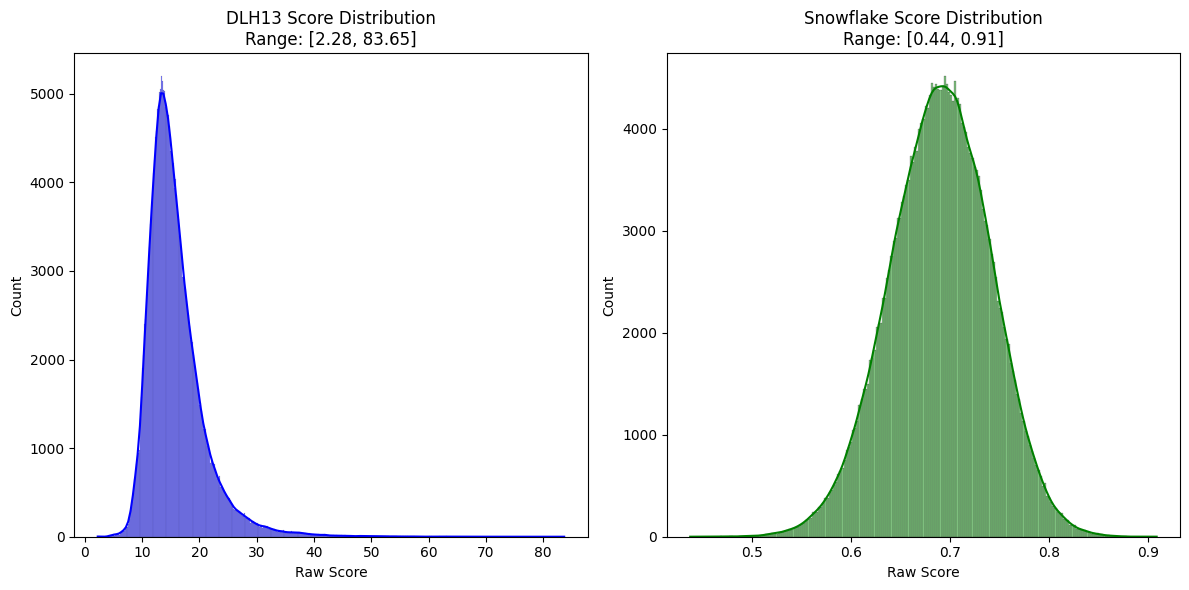

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Run both models separately to get raw scores
lexical_res = (pt.Transformer.from_df(run_dlh13) % 30).transform(queries_df)
dense_res = (sentence_model2.query_encoder() >> dense_index.scorer()).transform(lexical_res)

# Create Plot
plt.figure(figsize=(12, 6))

# Plot DLH13 (Lexical)
plt.subplot(1, 2, 1)
sns.histplot(lexical_res['score'], kde=True, color='blue')
plt.title(f"DLH13 Score Distribution\nRange: [{lexical_res['score'].min():.2f}, {lexical_res['score'].max():.2f}]")
plt.xlabel("Raw Score")

# Plot Snowflake (Dense)
plt.subplot(1, 2, 2)
sns.histplot(dense_res['score'], kde=True, color='green')
plt.title(f"Snowflake Score Distribution\nRange: [{dense_res['score'].min():.2f}, {dense_res['score'].max():.2f}]")
plt.xlabel("Raw Score")

plt.tight_layout()
plt.show()

## (Experimental Part) Cross-Encoder: ms-marco-MiniLM-L-2-v2

In [ ]:
from sentence_transformers import CrossEncoder
import pyterrier as pt

ce_model = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-2-v2')

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/62.5M [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

In [ ]:
def cross_encoder_rerank(df):
    if df.empty:
        return df
    pairs = list(zip(df['query'], df['text']))
    df['score'] = ce_model.predict(pairs, batch_size=32, show_progress_bar=True)
    return pt.model.add_ranks(df)

ce_reranker = pt.apply.generic(cross_encoder_rerank)

pipeline_ce_rerank = pt.Transformer.from_df(run_dlh13) % 30 >> ce_reranker

pt.Experiment(
    [pipeline_ce_rerank],
    queries_df,
    qrels_df,
    eval_metrics=[P@1, P@5, P@10, R@5, R@10, nDCG@5, nDCG@10, "map"],
    names=["Cross-Encoder Re-Rank"],
    verbose = True
)

pt.Experiment:   0%|          | 0/1 [00:00<?, ?system/s]

Batches:   0%|          | 0/9374 [00:00<?, ?it/s]

,name,map,P@1,P@5,P@10,R@5,R@10,nDCG@5,nDCG@10
0,Cross-Encoder Re-Rank,0.65504,0.5741,0.1497,0.08075,0.7485,0.8075,0.668422,0.687582


In [ ]:
pipeline_ce_rerank

(<pyterrier.transformer.SourceTransformer object at 0x7f231803c710> >> RankCutoff(30) >> pt.apply.generic())

## (Experimental Part) Dense Re-Ranking on pre-processed documents

https://pyterrier.readthedocs.io/en/latest/ext/pyterrier-dr/api.html#pyterrier_dr.BiEncoder

Prepare Text with Dates Column

In [ ]:
for index, row in corpus_dataframe_preprocessed.iterrows():
    dates_list = row["normalized_dates"]
    pub_date = str(row["publication_date"])
    combined_dates = list(set(dates_list + [pub_date]))

    # Format the string
    text_with_dates = f"{row['text']}\nRelevant Dates: {', '.join(combined_dates)}"

    # Write directly back to the dataframe using the index
    corpus_dataframe_preprocessed.at[index, "text_with_dates"] = text_with_dates

print(corpus_dataframe_preprocessed.iloc[2]["text_with_dates"])

At Westmoreland, Mrs. Sally Lincoln, wife of Mr. Spencer L. aged 28.  At Henrico, Mrs. Polly Adams, consort On Saturday, the 11th ult. Mr. Joseph Meyer, of Hampstead, was found dead in the road, (his horse standing by him) when oy e g e SMITH & RUST Pocket Book Lost.  "LOST last Wednesday between 7 and 8 o’clock in the afternoon, either in the Globe Tavern at the Plains, or on the road leading from thence to Portsmouth, a new Red Morocco Pocket Book ; containing some Money, Notes of hand payable to the Subscriber, also, New Hampshire Fire and Marine Certificates, and other papers valuable to none but to the owner—Whoever shall find said Pocket Book, and re- turn it with its contents, with or without the money shall be handsomely rewarded, and the thanks of their humble servant EDWARD. PARRY.  TO BE LET, That Fireproof Store lately improved by Mr. Benjamin Swett, which must be allowed to be the best stand for business, either for English or West- India Goods in this town—Inquire of EDWA

Prepare Text with Locations Column

In [ ]:
for index, row in corpus_dataframe_preprocessed.iterrows():
    locations_list = row["locations_text"]
    text_with_locations = f"{row['text']}\nRelevant Locations: {', '.join(locations_list)}"

    # Write directly back to the dataframe using the index
    corpus_dataframe_preprocessed.at[index, "text_with_locations"] = text_with_locations

print(corpus_dataframe_preprocessed.iloc[2]["text_with_locations"])

At Westmoreland, Mrs. Sally Lincoln, wife of Mr. Spencer L. aged 28.  At Henrico, Mrs. Polly Adams, consort On Saturday, the 11th ult. Mr. Joseph Meyer, of Hampstead, was found dead in the road, (his horse standing by him) when oy e g e SMITH & RUST Pocket Book Lost.  "LOST last Wednesday between 7 and 8 o’clock in the afternoon, either in the Globe Tavern at the Plains, or on the road leading from thence to Portsmouth, a new Red Morocco Pocket Book ; containing some Money, Notes of hand payable to the Subscriber, also, New Hampshire Fire and Marine Certificates, and other papers valuable to none but to the owner—Whoever shall find said Pocket Book, and re- turn it with its contents, with or without the money shall be handsomely rewarded, and the thanks of their humble servant EDWARD. PARRY.  TO BE LET, That Fireproof Store lately improved by Mr. Benjamin Swett, which must be allowed to be the best stand for business, either for English or West- India Goods in this town—Inquire of EDWA

Prepare Text with Named Entities column

In [ ]:
for index, row in corpus_dataframe_preprocessed.iterrows():
    entities_list = row["named_entities"]
    text_with_enitities = f"{row['text']}\nRelevant Entities: {', '.join(entities_list)}"

    # Write directly back to the dataframe using the index
    corpus_dataframe_preprocessed.at[index, "text_with_entities"] = text_with_enitities

print(corpus_dataframe_preprocessed.iloc[2]["text_with_entities"])

At Westmoreland, Mrs. Sally Lincoln, wife of Mr. Spencer L. aged 28.  At Henrico, Mrs. Polly Adams, consort On Saturday, the 11th ult. Mr. Joseph Meyer, of Hampstead, was found dead in the road, (his horse standing by him) when oy e g e SMITH & RUST Pocket Book Lost.  "LOST last Wednesday between 7 and 8 o’clock in the afternoon, either in the Globe Tavern at the Plains, or on the road leading from thence to Portsmouth, a new Red Morocco Pocket Book ; containing some Money, Notes of hand payable to the Subscriber, also, New Hampshire Fire and Marine Certificates, and other papers valuable to none but to the owner—Whoever shall find said Pocket Book, and re- turn it with its contents, with or without the money shall be handsomely rewarded, and the thanks of their humble servant EDWARD. PARRY.  TO BE LET, That Fireproof Store lately improved by Mr. Benjamin Swett, which must be allowed to be the best stand for business, either for English or West- India Goods in this town—Inquire of EDWA

In [ ]:
#sentence_model = SBertBiEncoder('sentence-transformers/all-MiniLM-L6-v2', device = "cuda") # Uses "text" field by default
#sentence_model = SBertBiEncoder('sentence-transformers/all-MiniLM-L6-v2', device = "cuda", text_field = "text_tc")
#sentence_model = SBertBiEncoder('sentence-transformers/all-MiniLM-L6-v2', device = "cuda", text_field = "text_tc_lem")
#sentence_model = SBertBiEncoder('sentence-transformers/all-MiniLM-L6-v2', device = "cuda", text_field = "text_with_dates")
#sentence_model = SBertBiEncoder('sentence-transformers/all-MiniLM-L6-v2', device = "cuda", text_field = "text_with_locations")
sentence_model = SBertBiEncoder('sentence-transformers/all-MiniLM-L6-v2', device = "cuda", text_field = "text_with_entities")

In [ ]:
#index_path = dense_index_path("all-MiniLM-L6-v2_index_tc")
#index_path = dense_index_path("all-MiniLM-L6-v2_index_lem")
#index_path = dense_index_path("all-MiniLM-L6-v2_index_te")
#index_path = dense_index_path("all-MiniLM-L6-v2_index_geo")
index_path = dense_index_path("all-MiniLM-L6-v2_index_ner")

dense_index = FlexIndex(index_path)

if os.path.exists(index_path) and os.listdir(index_path):
    dense_index.load(index_path)
    print("Index loaded from disk.")
else:
    os.makedirs(index_path, exist_ok=True)

    index_pipeline = sentence_model >> dense_index.indexer(mode="overwrite")
    index_pipeline.index(
        tqdm(
            corpus_dataframe_preprocessed.to_dict("records"),
            total=len(corpus_dataframe_preprocessed)
        )
    )
    print("Index created and saved.")

  0%|          | 0/131921 [00:00<?, ?it/s]

indexing: 0dvec [00:00, ?dvec/s]

Index created and saved.


In [ ]:
retrieval_pipeline_combined = (
    pt.Transformer.from_df(run_dlh13) % 50 >>
      ( 0.1 * pt.Transformer.identity() +
        0.9 * (sentence_model.query_encoder() >> dense_index.scorer())
      )
    )

pt.Experiment(
    [retrieval_pipeline_combined],
    queries_df,
    qrels_df,
    eval_metrics=[P@1, P@5, P@10, R@5, R@10, nDCG@5, nDCG@10, "map"],
    names=["Emp. Weights - NER"],
    verbose = True
)

0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/pyterrier/_evaluation/_validation.py:76: UserWarning: Experiment Pipeline Validation Report

The following pipelines could not be validated (i.e., it is unclear what outputs they produce):
 - Pipeline #0: Emp. Weights - NER ((<pyterrier.transformer.SourceTransformer object at 0x7adbf4938440> >> RankCutoff(50) >> <pyterrier._ops.Sum object at 0x7adbf4c5ed20>))
If these pipelines work, set validate='ignore' to remove this warning, or make them inspectable to clarify how they work.

See https://pyterrier.readthedocs.io/en/latest/troubleshooting/inspection.html for more information.
  warn(message)


pt.Experiment:   0%|          | 0/1 [00:00<?, ?system/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

,name,map,P@1,P@5,P@10,R@5,R@10,nDCG@5,nDCG@10
0,Emp. Weights - NER,0.718884,0.6466,0.16098,0.08531,0.8049,0.8531,0.73298,0.748663


# Phase 2: RAG

### Installation and import of libraries

Install dependencies

Note: it is necessary to upgrade bitsandbytes in case a quantization configurations needs to be used. In thic case a smaller model was adopted in order to avoid using quantization.

In [ ]:
!pip install -U bitsandbytes transformers accelerate -q

Import libraries

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

Check CUDA availability and version of main libraries

In [ ]:
print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)


Torch: 2.9.0+cu126
CUDA available: True
CUDA version: 12.6


### Prepare LLM model

In case of errors with LLM loading, it is worth trying to execute the following installation commands.

In [ ]:
#!pip install --upgrade transformers accelerate bitsandbytes
#!pip uninstall -y torch torchvision torchaudio
#!pip install torch torchvision torchaudio

Found existing installation: torch 2.10.0
Uninstalling torch-2.10.0:
  Successfully uninstalled torch-2.10.0
Found existing installation: torchvision 0.24.0+cu126
Uninstalling torchvision-0.24.0+cu126:
  Successfully uninstalled torchvision-0.24.0+cu126
Found existing installation: torchaudio 2.9.0+cu126
Uninstalling torchaudio-2.9.0+cu126:
  Successfully uninstalled torchaudio-2.9.0+cu126


Code adapted from: https://huggingface.co/google/gemma-3-1b-it. In that page it refers to the usage of the Gemma-3-1B model, while in this project it was modified in order to function with Qwen2.5-3B and Qwen2.5-1.5B.

In [ ]:
# This model requires to insert a HuggingFace token in the Colab environment
model_id = "Qwen/Qwen2.5-1.5B"

# For a smaller 1.5B model this is not used
quantization_config = BitsAndBytesConfig(
    load_in_16bit=True,
)

tokenizer = AutoTokenizer.from_pretrained(model_id)
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    #quantization_config=quantization_config,
    device_map="auto"
)

In [ ]:
def generate_rag_answer(query, documents, max_new_tokens = 512):
    # Combine retrieved documents into a single context block
    context = "\n\n".join([f"Document {i+1}:\n{doc}" for i, doc in enumerate(documents)])

    # Define the conversation template
    messages = [
        {"role": "system", "content": "You are a helpful assistant for answering historical " +
        "questions. Answer the question using ONLY the provided context from the newspapers." +
         "If the answer isn't in the context, say you don't know."},
        {"role": "user", "content": f"Context:\n{context}\n\nQuestion: {query}"}
    ]

    # Store raw prompt submitted to the LLM
    raw_prompt_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

    # Format prompt and generate
    input_ids = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        return_tensors="pt"
    ).to(model.device)

    outputs = model.generate(
        input_ids,
        max_new_tokens = max_new_tokens,
        do_sample = True,
        temperature = 0.1, # May be useful to conduct experiments with different temperature values
    )

    # Decode only the newly generated tokens
    response = tokenizer.decode(outputs[0][input_ids.shape[-1]:], skip_special_tokens=True)
    return response, raw_prompt_text

### Prepare Preprocessed Dataset

In [ ]:
corpus_dataframe_preprocessed = load_corpus_preprocessed()
corpus_dataframe_preprocessed = corpus_dataframe_preprocessed.rename(columns={"para_id": "docno", "context": "text"})
queries_df = load_queries_preprocessed()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Prepare Retrieval Pipeline

In [ ]:
# ---- First Stage Retrieval ----
# First Stage Retrieval: Index
index = load_or_build_terrier_index(
    "timeRetrieval_index", "text",
    lambda: corpus_dataframe_preprocessed.to_dict(orient="records"))

# First Stage Retrieval: Retriever
dlh13 = pt.terrier.Retriever(index, wmodel="DLH13", verbose = True)


# ---- Second Stage Retrieval ----
# Second Stage: Sentence Model
sentence_model3 = SBertBiEncoder('BAAI/bge-base-en-v1.5')

# Second Stage: Indexing
index_path = dense_index_path("bge-base-en-v1.5_index")
dense_index = FlexIndex(index_path)

if os.path.exists(index_path) and os.listdir(index_path):
  dense_index.load(index_path)
  print("Index loaded from disk.")
else:
  os.makedirs(index_path, exist_ok=True)
  index_pipeline = sentence_model3 >> dense_index.indexer(mode="overwrite")
  index_pipeline.index(tqdm(corpus_dataframe_preprocessed.to_dict("records"),
                            total=len(corpus_dataframe_preprocessed)))
  print("Index created and saved.")


# Complete pipeline
retrieval_pipeline = (
    dlh13 % 50 >>
      ( 0.1 * pt.Transformer.identity() +
        0.9 * (sentence_model3.query_encoder() >> dense_index.scorer())
      )
    )

retrieval_pipeline

Java started (triggered by IndexFactory.of) and loaded: pyterrier.java.colab, pyterrier.java, pyterrier.java.24, pyterrier.terrier.java [version=5.11 (build: craig.macdonald 2025-01-13 21:29), helper_version=0.0.8]


Index loaded from disk.
Index loaded from disk.


0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

(TerrierRetr(DLH13) >> RankCutoff(50) >> <pyterrier._ops.Sum object at 0x7a4e0f28b6b0>)

Test the Retrieval pipeline on a single query

In [ ]:
queries_df = queries_df.rename(columns={'query_id': 'qid', 'question': 'query'})[['qid', 'query']]
retrieval_pipeline.transform(queries_df.iloc[0:1]).head()

TerrierRetr(DLH13):   0%|          | 0/1 [00:00<?, ?q/s]

  0%|          | 0/1 [00:00<?, ?it/s]

,qid,docid,docno,score,query,query_vec,rank
0,test_1,93683,Arkansas_18950302_19,1.220090,How many lots did Thomas Peirce have,"[-0.04195794, -0.0462349, -0.07952566, 0.01392...",48
1,test_1,28933,California_18581022_17,1.257532,How many lots did Thomas Peirce have,"[-0.04195794, -0.0462349, -0.07952566, 0.01392...",42
2,test_1,99909,Connecticut__18961224_22,1.454842,How many lots did Thomas Peirce have,"[-0.04195794, -0.0462349, -0.07952566, 0.01392...",25
3,test_1,103551,Delaware_18920928_1,1.230387,How many lots did Thomas Peirce have,"[-0.04195794, -0.0462349, -0.07952566, 0.01392...",46
4,test_1,79383,Florida_18890326_4,1.231010,How many lots did Thomas Peirce have,"[-0.04195794, -0.0462349, -0.07952566, 0.01392...",45


### QA Example

Retrieve documents relevant to the query

In [ ]:
top_k_llm = 7

# Build single-query dataframe
qid = "test"
query = queries_df.iloc[0]["query"]
query_df = pd.DataFrame([{
    "qid": qid,
    "query": query
}])

# Obtain relevant documents
results = retrieval_pipeline.transform(query_df)
results = results.sort_values("score", ascending=False)
top_results = results.head(top_k_llm)

# Prepare retrieved documents
docnos = top_results["docno"].tolist()
retrieved_docs = []
for docno in docnos:
    doc_row = corpus_dataframe_preprocessed[
        corpus_dataframe_preprocessed["docno"] == docno
    ]
    if not doc_row.empty:
        retrieved_docs.append(doc_row["text"].iloc[0])
    else:
        print(f"Warning: docno {docno} not found in corpus_dataframe_preprocessed. Skipping.")

print(retrieved_docs)
print("Number of retrieved docs:", len(retrieved_docs))


TerrierRetr(DLH13):   0%|          | 0/1 [00:00<?, ?q/s]

  0%|          | 0/1 [00:00<?, ?it/s]

["In Gloucester county, (N.J.) on the 8th ult. THOMAS SEEDE, a native of the county, aged 104 years, 1 month & 20 days. It is worthy of remark that there have died in this county within the space of two years, three citizens, whose ages together amount to upwards of 317 years.  In this town, Mr. GEORGE Hart; A child of Mr. Gold, and a child of Mr. Thomas Peirce. NOTICE—MAPS OF THE UNITED STATES. NEW, correct and beautifully varnished MAPS of the United States, various prices just received and for sale at the Book store of C. PEIRCE, Daniel street, Portsmouth, where may also be had Account Books, of almost all sizes, prices and qualities. Also A fresh supply of BOOKS & STATIONERY; Penknives; Razors; Scissors; Inkstands; Ink Powder; Wafers; Black- Sand; Marking Ink for Linen; Wash- balls; best Windsor Soap; Ivory and bone paper Folders and Cutters; silver Pencil Cases and Pencils; Morocco-Pocket and Memorandum Books; Ladies' Pocket Books and", "The limits of this Can! forbids the publica

Generate answer

In [ ]:
answer, _ = generate_rag_answer(query, retrieved_docs)
print(f"Answer: {answer}")

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:151643 for open-end generation.
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


Answer: The answer to this question is: Thomas Peirce had 18 lots.


### RAG: Evaluation

In [ ]:
import os
import pandas as pd
from tqdm.auto import tqdm

QUERIES_PER_RUN = 30

# Output folder (local). Pre-computed runs are available on HF in QA_RUNS_HF
output_dir = QA_RUNS_LOCAL
os.makedirs(output_dir, exist_ok=True)

# Define the Metadata Runs
metadata_runs = [
    "text",
    "text_tc",
    "text_tc_lem",
    "named_entities"
    "locations_text",
    "normalized_dates",
    "publication_date",
    "ner_dates"
]

# Process the first 30 queries
top_queries = queries_df.head(QUERIES_PER_RUN).copy()
top_k_llm = 7

# ---- Main Loop ----
for meta_type in metadata_runs:
    print(f"\n Starting Run: {meta_type}")
    run_results = []

    for idx, row in tqdm(top_queries.iterrows(), total=QUERIES_PER_RUN):
        qid = row['qid']
        query_text = row['query']

        # Build query dataframe for retrieval
        query_df_item = pd.DataFrame([{"qid": qid, "query": query_text}])

        # Obtain relevant documents
        results = retrieval_pipeline.transform(query_df_item)
        results = results.sort_values("score", ascending=False)
        top_results = results.head(top_k_llm)

        docnos = top_results["docno"].tolist()
        retrieved_docs_with_meta = []

        for docno in docnos:
            doc_row = corpus_dataframe_preprocessed[
                corpus_dataframe_preprocessed["docno"] == docno
            ].iloc[0]

            original_text = doc_row["text"]

            # Manage cases of different injection of different types of metadata
            if meta_type in ["text", "text_tc", "text_tc_lem"]:
                enriched_text = doc_row.get(meta_type, doc_row["text"])
            else:
              if meta_type == "normalized_dates" or "ner_dates":
                # Combine normalized date and publication date
                dates_list = doc_row["normalized_dates"] if isinstance(doc_row["normalized_dates"], list) else []
                pub_date = str(doc_row["publication_date"])
                combined_dates = list(set(dates_list + [pub_date])) # unique dates
                meta_content = f"Relevant Dates: {', '.join(combined_dates)}"
                if meta_type == "ner_dates":
                  entities = doc_row["named_entities"]
                  meta_content += f"\nRelevant Entities: {', '.join(entities)}"

              else:
                # Metadata from the corresponding column
                meta_val = doc_row[meta_type]
                meta_content = f"{meta_type.replace('_', ' ').title()}: {meta_val}"

              # Combine original text with the specific metadata for this run
              enriched_text = f"{original_text}\n[{meta_content}]"

            retrieved_docs_with_meta.append(enriched_text)

        # Generate Answer
        answer, full_llm_prompt = generate_rag_answer(query_text, retrieved_docs_with_meta)

        # Store data for this specific query
        run_results.append({
            "qid": qid,
            "query": query_text,
            "meta_type": meta_type,
            "full_prompt": full_llm_prompt,
            "answer": answer,
            "retrieved_docnos": docnos
        })

    # Save the dataframe for this specific run
    run_df = pd.DataFrame(run_results)
    save_path = os.path.join(output_dir, f"run_{meta_type}.csv")
    run_df.to_csv(save_path, index=False)
    print(f"Saved results to {save_path}")

print(f"\nAll {QUERIES_PER_RUN} queries processed across all metadata runs!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

 Starting Run: text_tc_lem


  0%|          | 0/30 [00:00<?, ?it/s]

TerrierRetr(DLH13):   0%|          | 0/1 [00:00<?, ?q/s]

  0%|          | 0/1 [00:00<?, ?it/s]

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:151643 for open-end generation.


TerrierRetr(DLH13):   0%|          | 0/1 [00:00<?, ?q/s]

... (175 outputs left out)

TerrierRetr(DLH13):   0%|          | 0/1 [00:00<?, ?q/s]

  0%|          | 0/1 [00:00<?, ?it/s]

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:151643 for open-end generation.


Saved results to /content/drive/MyDrive/projectIR/projectIR/qa_runs/run_named_entities.csv

All 30 queries processed across all metadata runs!


Prepare "query - answer" pairs

In [ ]:
queries_answers_df = pd.DataFrame(queries, columns=["query_id", "question", "answer",  "org_answer"])
queries_answers_df = queries_answers_df.rename(columns={"answer": "answer_gt"})
queries_answers_df.head()

,query_id,question,answer_gt,org_answer
0,test_1,How many lots did Thomas Peirce have,183,183
1,test_10,Who gave Hamilton the substance of what he had...,Taylor,Taylor
2,test_100,Who informs his FRIENDS and the PUBLIC that he...,WILLIAM EATON,WILLIAM EATON
3,test_1000,Who was the Secretary of the Treasury of the U...,Jeremiah Parker,Jeremiah Parker
4,test_10000,Who made a speech in front of the Brooks House,John M. Wilson,John M. Wilson


#### Metrics

In [ ]:
!pip install rouge-score nltk -q

  Preparing metadata (setup.py) ... done


In [ ]:
from sentence_transformers import SentenceTransformer, util
import re
from rouge_score import rouge_scorer
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize

scorer = rouge_scorer.RougeScorer(["rougeL", "rouge1"], use_stemmer=True)
embedder = sentence_model3.model

def normalize(text):
    text = text.lower()
    text = re.sub(r'\W+', ' ', text)
    return text.strip()


def exact_match(pred, gold):
    return int(normalize(pred) == normalize(gold))


def f1_score(pred, gold):
    pred_tokens = normalize(pred).split()
    gold_tokens = normalize(gold).split()
    common = set(pred_tokens) & set(gold_tokens)
    if not common:
        return 0.0

    precision = len(common) / len(pred_tokens)
    recall = len(common) / len(gold_tokens)
    return 2 * precision * recall / (precision + recall)

# https://pypi.org/project/rouge-score/
def rouge_l(pred, gold):
    score = scorer.score(gold, pred)
    return score["rougeL"].fmeasure

# https://pypi.org/project/rouge-score/
def rouge_1(pred, gold):
    score = scorer.score(gold, pred)
    return score["rouge1"].fmeasure

# https://www.nltk.org/api/nltk.translate.bleu
# https://stackoverflow.com/questions/40542523/nltk-corpus-level-bleu-vs-sentence-level-bleu-score
# The addoption of the SmoothingFunction is motivated by the following warning messages that were
# shown during tests with BLEU.
# "The hypothesis contains 0 counts of 2-gram overlaps.
# Therefore the BLEU score evaluates to 0, independently of
# how many N-gram overlaps of lower order it contains.
# Consider using lower n-gram order or use SmoothingFunction()""
def bleu(pred, ref):
    chencherry  = SmoothingFunction()
    pred_tokens = word_tokenize(pred.lower())
    ref_tokens = [word_tokenize(ref.lower())]  # single reference wrapped in list
    score = sentence_bleu(ref_tokens, pred_tokens, smoothing_function = chencherry.method1)
    return score


def semantic_similarity(pred, gold):
    emb1 = embedder.encode(pred, convert_to_tensor=True)
    emb2 = embedder.encode(gold, convert_to_tensor=True)
    return util.cos_sim(emb1, emb2).item()

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [ ]:
# Ground-truth answers
gt_answers = (
    queries_answers_df
    .set_index("query_id")["answer_gt"]
    .to_dict()
)

run_files = [
    "run_text.csv",
    "run_text_tc.csv",
    "run_text_tc_lem.csv",
    "run_named_entities.csv",
    "run_locations_text.csv",
    "run_publication_date.csv",
    "run_normalized_dates.csv",
    "run_ner_dates.csv"
]

def evaluate_run(run_df, gt_answers):
    metrics = []

    for _, row in run_df.iterrows():
        qid = row["qid"]
        pred = row["answer"]

        gt = gt_answers.get(qid)
        if gt is None:
            continue

        metrics.append({
            "exact_match": exact_match(pred, gt),
            "f1": f1_score(pred, gt),
            "rougeL": rouge_l(pred, gt),
            "rouge1": rouge_1(pred, gt),
            "bleu": bleu(pred, gt),
            "semantic_sim": semantic_similarity(pred, gt)
        })

    return pd.DataFrame(metrics).mean(numeric_only=True)

In [ ]:
summaries = []

for run_file in run_files:
    # Use runs generated in this session if present, otherwise the pre-computed ones from HF
    run_path = first_existing(os.path.join(QA_RUNS_LOCAL, run_file), os.path.join(QA_RUNS_HF, run_file))
    if run_path is None:
        print(f"Missing run: {run_file}")
        continue
    run_df = pd.read_csv(run_path)

    summary = evaluate_run(run_df, gt_answers)
    summary["run"] = run_file.replace(".csv", "")

    summaries.append(summary)

final_results = pd.DataFrame(summaries)
final_results = final_results.set_index("run")

pd.set_option('display.float_format', '{:.4f}'.format)
display(final_results)

,exact_match,f1,rougeL,rouge1,bleu,semantic_sim
run,,,,,,
run_text,0.0000,0.0571,0.0571,0.0571,0.0072,0.5388
run_text_tc,0.0000,0.0393,0.0393,0.0393,0.0044,0.5128
run_text_tc_lem,0.0000,0.0345,0.0345,0.0345,0.0029,0.5053
run_named_entities,0.0000,0.0678,0.0682,0.0682,0.0093,0.5276
run_locations_text,0.0000,0.0862,0.0862,0.0862,0.0113,0.5391
run_publication_date,0.0000,0.0804,0.0808,0.0808,0.0108,0.5468
run_normalized_dates,0.0000,0.0710,0.0710,0.0710,0.0099,0.5391
run_ner_dates,0.0000,0.0816,0.0930,0.0930,0.0106,0.5468
